# Notebook B: tám lần chia theo quý, bốn mô hình, RQ2 và RQ3

**Đề tài:** *What Each Data Repair Step Is Worth in Next-Hour Traffic Forecasting on the Istanbul Open Data and What Happens on Holidays*

**Sinh viên B** chạy sau khi Notebook A in `all checks passed`. Notebook này không cần kernel của Notebook A.

| Phần | Câu hỏi | Bảng chính |
|---|---|---|
| Bước 6a | **RQ2:** mô hình nào dự báo giờ kế tiếp tốt nhất, so với ba mốc đơn giản, qua 8 quý test | `table_rq2.csv`, `table_rq2_by_fold.csv` |
| Bước 6b | **RQ3a:** mỗi bậc sửa dữ liệu làm sai số đổi bao nhiêu | `table_rq3_repair_ladder*.csv` |
| Bước 6c | **RQ3b:** holiday echo và năm cách xử lý lag tuần (L0–L4) | `table_rq3_weekly_lag_variants.csv`, `table_rq3_wilcoxon.csv`, `table_rq3_event_study.csv` |
| Bước 6d | Kiểm chứng cơ chế, con số lạc quan khi bỏ qua bước sửa | `table_rq3_mechanism.csv`, `table_rq3_optimism.csv` |

**Thời gian chạy:** khoảng 1 giờ trên laptop 4 nhân (8 quý × 4 mô hình × khoảng 10 cấu hình). Kết quả từng quý được lưu vào `report/cache/`; nếu bị ngắt, chạy lại sẽ bỏ qua các quý đã xong. Đặt `FAST = True` để chạy thử nhanh (2 quý, mô hình nhỏ) trước khi chạy thật.

## Kiểm tra bàn giao và cấu hình

- **Làm gì:** đọc `manifest.json`, so mã băm các file parquet, khai báo cấu hình thực nghiệm.
- **Vì sao:** bảo đảm hai notebook dùng cùng một dữ liệu; mọi tham số thực nghiệm nằm ở một chỗ, **cố định trước khi xem kết quả test**.
- **Kiểm tra:** ô in `handover ok`.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm matplotlib scipy

In [ ]:
import os, json, time, hashlib, gc, warnings
from pathlib import Path
if Path.cwd().name == 'Source Code': os.chdir(Path.cwd().parent)          # notebooks live in 'Source Code/'; data/, report/ and sql/ are one level up
print('working folder:', Path.cwd())
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

FAST = False                 # True: quick test run (2 folds, small models); set False for the results of the paper
RERUN = False                # True: ignore the cached folds in report/cache and recompute everything
SEEDS = [0, 1, 2]            # seeds of the main configuration (RQ2); every other configuration uses seed 0
TRAIN_CAP = 150_000          # training rows per fit, sampled with a fixed random rank
MIN_TEST_COVERAGE = 0.5      # a cell is scored in a test quarter only if it reports at least half of the hours (rule fixed in advance)
ET_TREES, LGB_ROUNDS, MLP_ITER = 200, 600, 60
IMP_REPEATS, IMP_ORDINARY_ROWS = 3, 100_000   # factor impact: shuffles per factor group, ordinary rows sampled per quarter (all week-after-holiday rows are kept)
EXCLUDE_FOLD = '2024-Q1'     # quarter hit by the level break; RQ2 also reports the mean without it (rule fixed in advance)
if FAST: SEEDS, TRAIN_CAP, ET_TREES, LGB_ROUNDS, MLP_ITER, IMP_REPEATS, IMP_ORDINARY_ROWS = [0], 30_000, 40, 150, 15, 1, 20_000

PROC, REPORT = Path('data/processed'), Path('report'); CACHE = REPORT / ('cache_fast_v2' if FAST else 'cache_v2')       # v2: results after the data fixes; the old cache is not used
CACHE.mkdir(parents=True, exist_ok=True)
def md5(p, block=1 << 22):
    h = hashlib.md5()
    with open(p, 'rb') as fh:
        for b in iter(lambda: fh.read(block), b''): h.update(b)
    return h.hexdigest()
man = json.load(open(PROC / 'manifest.json'))
for name, meta in man['files'].items():
    assert md5(PROC / name) == meta['md5'], f'{name} differs from the manifest: rerun Notebook A'
SELECT_YEAR = man['config']['select_year']
def save(df, name): df.to_csv(REPORT / name, index=False); return df
print('handover ok |', man['feat_rows'], 'feature rows | months missing:', man['months_missing'] or 'none', '| FAST =', FAST)

working folder: d:\Next-Hour Traffic Forecasting
handover ok | 3945450 feature rows | months missing: none | FAST = False


## Bước 4a. Bảng đặc trưng và năm cách tạo lag tuần

- **Làm gì:** đọc `feat.parquet` (lag tạo bằng SQL trên lưới giờ đầy đủ ở Notebook A), tạo năm phiên bản lag tuần, nhóm loại ngày của **giờ mục tiêu**, và các cờ dùng để chấm điểm.
- **Năm phiên bản lag tuần** (đều chỉ dùng quá khứ):

| Mã | Lag tuần | Ý tưởng |
|---|---|---|
| L0 | `lag167` (168 giờ trước mục tiêu) | Cách làm phổ biến, là cấu hình chính của RQ2 |
| L1 | không có | Bỏ hẳn lag tuần |
| L2 | tuần thường gần nhất | Nếu tuần trước là ngày lễ thì lấy 2 tuần trước, nếu cả hai là lễ thì lấy 3 tuần trước |
| L3 | trung vị của 1, 2, 3 tuần trước | Bền với một tuần bất thường |
| L4 | L0 + `holiday_last_week` + `days_since_holiday` | Cho mô hình biết lag tuần đang trỏ vào ngày lễ |

- **Kiểm tra:** số dòng, tỷ lệ dòng có đủ đặc trưng, số dòng theo nhóm ngày.

In [3]:
f = pd.read_parquet(PROC / 'feat.parquet')
for c in ['ts', 'ts_y']: f[c] = f[c].astype('datetime64[ns]')
for c in f.columns:
    if f[c].dtype == 'float64': f[c] = f[c].astype('float32')
cells = pd.read_csv('data/cells_selected.csv')
f['lag_week_L0'] = f.lag167
l2 = np.where(f.holiday_last_week_y == 1, np.where(f.holiday_2w_y == 1, f.lag503, f.lag335), f.lag167)
f['lag_week_L3'] = np.nanmedian(np.c_[f.lag167, f.lag335, f.lag503], axis=1).astype('float32')
f['lag_week_L2'] = pd.Series(l2, index=f.index).fillna(f.lag_week_L3).astype('float32')
GROUP = {'special_event': 'special_event', 'holiday': 'holiday', 'arife': 'arife', 'admin_leave': 'bridge_day', 'week_after_holiday': 'week_after_holiday'}
f['group'] = f.day_type_y.map(GROUP).fillna('ordinary')
f['score_ok'] = (f.y.notna() & (f.outage_y == 0) & (f.partial_y == 0) & (f.fault_y == 0)).astype(bool)   # outage and faulty hours are never scored          # outage hours are never scored (rule fixed in advance)
CORE = ['volume', 'lag1', 'lag2', 'lag23', 'lag167', 'speed']            # L2 and L3 fall back on lag167, so they never add missing inputs
f['core_ok'] = f[CORE].notna().all(axis=1)                                                     # every grid configuration has its inputs
f['clean_now'] = ((f.outage_now == 0) & (f.partial_now == 0) & (f.fault_now == 0)).astype(bool)
f['rk'] = np.random.default_rng(0).random(len(f)).astype('float32')                            # fixed random rank for training samples

BASE = ['volume', 'lag1', 'lag2', 'lag23', 'speed']
TIME = ['hour_sin', 'hour_cos', 'dow_y', 'is_weekend_y']
CALF = ['is_holiday_y', 'is_arife_y', 'is_admin_leave_y', 'is_ramadan_y', 'is_school_break_y', 'is_special_event_y']
LOC = ['cell_mean', 'lat', 'lon']                                                              # cell_mean: mean log volume of the cell in the training period
WEEK = {'L0': ['lag_week_L0'], 'L1': [], 'L2': ['lag_week_L2'], 'L3': ['lag_week_L3'], 'L4': ['lag_week_L0', 'holiday_last_week_y', 'days_since_holiday_y']}
print(f'{len(f):,} rows | with all inputs: {f.core_ok.mean():.1%} | scorable targets: {f.score_ok.mean():.1%}')
print(f[f.core_ok & f.score_ok].group.value_counts().to_string())

3,945,450 rows | with all inputs: 84.6% | scorable targets: 93.7%
group
ordinary              2949068
week_after_holiday     156470
holiday                135153
special_event           50257
arife                   19650
bridge_day               7200


## Bước 4b. Tám lần chia theo quý (rolling origin, cửa sổ mở rộng)

- **Làm gì:** năm `SELECT_YEAR` chỉ dùng để huấn luyện. Mỗi quý sau đó lần lượt là tập test; tập huấn luyện là **mọi giờ có mục tiêu trước ngày đầu quý test**.
- **Vì sao:** mỗi kỳ lễ nằm trong tập test đúng một lần; mọi lần chia đều có ví dụ ngày lễ và tuần sau lễ của năm trước trong tập huấn luyện. Độ lệch chuẩn qua 8 quý cho biết kết quả ổn định đến đâu theo mùa.
- **Quy tắc chấm điểm (cố định trước):** chỉ chấm giờ mục tiêu không thuộc giờ mất dữ liệu; chỉ chấm ô có dữ liệu ở ít nhất 50% số giờ của quý test; sự kiện đặc biệt báo riêng, không tính vào MAE chính.
- **Kiểm tra:** bảng các lần chia, số dòng test và số ngày lễ trong mỗi quý.

In [4]:
quarters = sorted(q for q in f.quarter.unique() if int(q[:4]) > SELECT_YEAR)
FOLDS = []
for qn in quarters:
    y, k = int(qn[:4]), int(qn[-1]); start = pd.Timestamp(y, 3 * k - 2, 1); end = start + pd.DateOffset(months=3)
    te = (f.ts >= start) & (f.ts_y < end)
    cov = f[te].groupby('cell').volume.apply(lambda s: s.notna().mean())
    ok_cells = set(cov[cov >= MIN_TEST_COVERAGE].index)
    E = te & f.score_ok & f.core_ok & f.cell.isin(ok_cells)
    FOLDS.append({'fold': qn, 'start': start, 'end': end, 'cells_scored': len(ok_cells), 'test_rows': int(E.sum()),
                  'train_rows_available': int(((f.ts_y < start) & f.score_ok).sum()),
                  'holiday_days': int(f[E & (f.group == 'holiday')].ts_y.dt.normalize().nunique()),
                  'week_after_holiday_days': int(f[E & (f.group == 'week_after_holiday')].ts_y.dt.normalize().nunique())})
FOLDS = pd.DataFrame(FOLDS); FOLDS = FOLDS[FOLDS.test_rows > 0].reset_index(drop=True)
if FAST: FOLDS = FOLDS.iloc[[0, 1]]
save(FOLDS.astype({'start': str, 'end': str}), 'table_folds.csv'); display(FOLDS)

,fold,start,end,cells_scored,test_rows,train_rows_available,holiday_days,week_after_holiday_days
0,2023-Q1,2023-01-01,2023-04-01,150,303440,1277100,1,1
1,2023-Q2,2023-04-01,2023-07-01,150,259334,1594950,8,6
2,2023-Q3,2023-07-01,2023-10-01,150,256631,1899450,3,7
3,2023-Q4,2023-10-01,2024-01-01,150,233550,2205748,1,2
4,2024-Q1,2024-01-01,2024-04-01,150,225485,2499598,1,1
5,2024-Q2,2024-04-01,2024-07-01,150,264235,2770348,10,12
6,2024-Q3,2024-07-01,2024-10-01,150,313800,3072898,2,2
7,2024-Q4,2024-10-01,2025-01-01,150,276650,3400648,1,2


## Bước 4c. Bảng "chưa sửa" cho thang sửa dữ liệu

- **Làm gì:** từ `traffic_raw.parquet` (bản ghi thô của 150 ô), tạo đặc trưng **theo thứ tự dòng** như phần lớn notebook vẫn làm: `shift(1)` là "giờ trước", `shift(-1)` là "giờ sau". Bậc R0 dùng nguyên bản ghi; bậc R1 gộp trùng trước.
- **Vì sao:** đây là điểm xuất phát của thang sửa dữ liệu. Bảng in ra cho biết bao nhiêu % lag và mục tiêu theo thứ tự dòng **không đúng** khoảng cách giờ.
- **Kiểm tra:** `table_rq3_time_axis_artefact.csv`.

In [5]:
H1 = pd.Timedelta(hours=1)
def repair(d, dedupe=True):                                   # copy of Notebook A, Step 2b (only the dedupe switch is needed here)
    d = d.sort_values(['cell', 'ts'], kind='stable')
    if dedupe: d = d.groupby(['cell', 'ts'], as_index=False).agg(vehicles=('vehicles', 'mean'), speed=('speed', 'mean'))
    return d.reset_index(drop=True)
def row_order_table(d):
    d = d.sort_values(['cell', 'ts'], kind='stable').reset_index(drop=True); g = d.groupby('cell', sort=False); v = g.vehicles; t_ = g.ts
    t = pd.DataFrame({'cell': d.cell, 'ts': d.ts, 'volume': d.vehicles.astype('float32'), 'speed': d.speed.astype('float32')})
    t['y_rec'] = v.shift(-1); t['ts_next'] = t_.shift(-1)
    for k, c in [(1, 'lag1'), (2, 'lag2'), (23, 'lag23'), (167, 'lag_week_L0')]: t[c] = v.shift(k).astype('float32')
    t['lag1_is_1h'] = (d.ts - t_.shift(1)) == H1; t['lagw_is_1w'] = (d.ts - t_.shift(167)) == 167 * H1; t['next_is_1h'] = (t.ts_next - d.ts) == H1
    nxt = d.ts + H1                                           # calendar of the next hour, computed from the clock as usual
    t['hour_sin'] = np.sin(2 * np.pi * nxt.dt.hour / 24).astype('float32'); t['hour_cos'] = np.cos(2 * np.pi * nxt.dt.hour / 24).astype('float32')
    t['dow_y'] = nxt.dt.dayofweek.astype('int8'); t['is_weekend_y'] = (t.dow_y >= 5).astype('int8')
    t = t.merge(cells[['cell', 'lat', 'lon']], on='cell', how='left')
    t['rk'] = np.random.default_rng(1).random(len(t)).astype('float32')
    return t
rawrec = pd.read_parquet(PROC / 'traffic_raw.parquet'); rawrec['ts'] = rawrec.ts.astype('datetime64[ns]')
HAS_DUP = bool(rawrec.duplicated(['cell', 'ts']).any())
RAWT = {'R0': row_order_table(repair(rawrec, dedupe=False))}
RAWT['R1'] = row_order_table(repair(rawrec, dedupe=True)) if HAS_DUP else RAWT['R0']   # no duplicates: R1 equals R0
del rawrec; gc.collect()
art = pd.DataFrame([[k, len(t), 100 * (1 - t.lag1_is_1h[t.lag1.notna()].mean()), 100 * (1 - t.lagw_is_1w[t.lag_week_L0.notna()].mean()),
                     100 * (1 - t.next_is_1h[t.y_rec.notna()].mean())] for k, t in RAWT.items()] +
                   [['R2+ hourly grid', int(f.volume.notna().sum()), 0.0, 0.0, 0.0]],
                   columns=['table', 'rows', 'pct_lag1_not_1h', 'pct_weekly_lag_not_1w', 'pct_target_not_next_hour'])
save(art.round(3), 'table_rq3_time_axis_artefact.csv'); display(art.round(3)); print('duplicates in the raw records:', HAS_DUP)

,table,rows,pct_lag1_not_1h,pct_weekly_lag_not_1w,pct_target_not_next_hour
0,R0,3708004,0.522,45.728,0.522
1,R1,3708004,0.522,45.728,0.522
2,R2+ hourly grid,3707854,0.000,0.000,0.000


duplicates in the raw records: False


## Bước 5. Mô hình, cấu hình và vòng lặp tám quý

**Bốn mô hình** (mỗi mô hình đại diện một cách dùng lag tuần):

| Mô hình | Họ | Vai trò trong kết luận |
|---|---|---|
| Ridge | tuyến tính | hệ số đọc được, kiểm chứng "mô hình dựa vào lag tuần bao nhiêu" |
| Extra Trees | rừng cây (bagging) | đại diện nhóm rừng |
| LightGBM | cây tăng cường, mô hình toàn cục với `cell` là biến phân loại | chuẩn hiện nay cho dữ liệu bảng nhiều chuỗi |
| MLP | mạng nơ-ron nhỏ | đối chứng học sâu |

Mọi mô hình học trên `log1p(số xe)` (cả mục tiêu và các đầu vào là số xe) rồi đổi ngược, để ô đông không lấn át ô vắng và để Ridge, MLP có quan hệ gần tuyến tính.

**Ba mốc:** Persistence (giờ sau = giờ này), cùng giờ tuần trước (L0), trung vị cùng giờ 3 tuần trước (L3).

**Cấu hình** (thang sửa dữ liệu R0–R5 và các phiên bản lag tuần L0–L4):

| Cấu hình | Dữ liệu | Đầu vào | Tập huấn luyện |
|---|---|---|---|
| R0 raw records | bản ghi thô, lag theo thứ tự dòng | cơ bản + thời gian + vị trí + lag tuần | mục tiêu = dòng kế tiếp |
| R1 + one row per cell and hour | gộp trùng | như R0 | như R0 |
| R2 + hourly grid | lưới giờ đầy đủ | như R0 | mục tiêu = giờ kế tiếp thật |
| R3 + outage and faulty hours left out | như R2 | như R0 | bỏ giờ mất dữ liệu |
| **R4 + calendar = MAIN** (L0) | như R2 | + lịch | như R3 |
| R5 + holiday-aware weekly lag (= L2) | như R2 | lịch + L2 | như R3 |
| L1, L3, L4 | như R4 | lịch + phiên bản lag tuần tương ứng | như R3 |

- **Mức ảnh hưởng của các nhóm yếu tố** (Bước 6e) được tính trong vòng lặp này, trên cấu hình chính, seed 0, cho cả 4 mô hình.
- **Kiểm tra:** mỗi quý in thời gian chạy; dòng `assert` bảo đảm mọi mục tiêu huấn luyện đứng trước giờ test đầu tiên.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor
MODELS = ['Ridge', 'Extra Trees', 'LightGBM', 'MLP']
def make_model(name, seed):
    if name == 'Ridge': return make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    if name == 'Extra Trees': return ExtraTreesRegressor(n_estimators=ET_TREES, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=seed)
    if name == 'LightGBM': return LGBMRegressor(n_estimators=LGB_ROUNDS, learning_rate=0.05, num_leaves=63, min_child_samples=50, subsample=0.8,
                                                subsample_freq=1, colsample_bytree=0.8, random_state=seed, n_jobs=-1, verbose=-1)
    return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), batch_size=512, max_iter=MLP_ITER, early_stopping=True,
                                                        n_iter_no_change=5, random_state=seed))
CELL_T = pd.CategoricalDtype(sorted(cells.cell))
COUNTS = ['volume', 'lag1', 'lag2', 'lag23', 'lag_week_L0', 'lag_week_L2', 'lag_week_L3']
def design(d, feats, name):
    X = d[feats].astype('float32')
    lc = [c for c in feats if c in COUNTS]; X[lc] = np.log1p(X[lc].clip(lower=0))     # counts on the log scale, like the target
    if name == 'LightGBM': X = X.assign(cell=d.cell.astype(CELL_T))          # global model: the cell is a categorical input
    return X
def fit_predict(name, seed, tr, te, feats, target):
    m = make_model(name, seed); t0 = time.perf_counter()
    m.fit(design(tr, feats, name), np.log1p(tr[target].to_numpy(dtype='float64'))); secs = time.perf_counter() - t0
    p = np.clip(np.expm1(m.predict(design(te, feats, name))), 0, None).astype('float32')
    return p, m, secs
def sample(mask, rk, cap=TRAIN_CAP):
    idx = np.flatnonzero(mask)
    return idx if len(idx) <= cap else idx[np.argsort(rk[idx])[:cap]]
def with_cell_mean(tr, *others, target='y'):
    cm = np.log1p(tr[target].astype('float64')).groupby(tr.cell).mean()
    return [d.assign(cell_mean=d.cell.map(cm).astype('float32')) for d in (tr,) + others]

GRID_CFG = {                                                     # name: (input features, drop outage hours from training)
    'R2 + hourly grid': (BASE + TIME + LOC + WEEK['L0'], False),
    'R3 + outage and faulty hours left out': (BASE + TIME + LOC + WEEK['L0'], True),
    'MAIN (R4 + calendar, L0)': (BASE + TIME + CALF + LOC + WEEK['L0'], True),
    'L1 no weekly lag': (BASE + TIME + CALF + LOC + WEEK['L1'], True),
    'L2 normal-week lag (R5)': (BASE + TIME + CALF + LOC + WEEK['L2'], True),
    'L3 median of 3 weeks': (BASE + TIME + CALF + LOC + WEEK['L3'], True),
    'L4 weekly lag + holiday flags': (BASE + TIME + CALF + LOC + WEEK['L4'], True)}
RAW_FEATS = BASE + TIME + LOC + WEEK['L0']
# factor impact (grouped permutation importance) on the main configuration
IMP_GROUPS = {'Recent traffic': ['volume', 'lag1', 'lag2', 'speed'], 'Same hour last week': ['lag_week_L0'],
              'Same hour yesterday': ['lag23'], 'Time of day/week': ['hour_sin', 'hour_cos', 'dow_y', 'is_weekend_y']}
def factor_impact(m, name, te, feats, y, day_group, seed=0):
    X = design(te, feats, name); y = np.asarray(y, dtype='float64')
    pred = lambda Z: np.clip(np.expm1(m.predict(Z)), 0, None)
    base = pred(X); masks = {g: (day_group == g) for g in ['ordinary', 'week_after_holiday']}
    groups = dict(IMP_GROUPS); groups['All other'] = [c for c in X.columns if not any(c in v for v in IMP_GROUPS.values())]
    rng = np.random.default_rng(seed); out = {}
    for grp, cols in groups.items():
        cols = [c for c in cols if c in X.columns]; d = {g: [] for g in masks}
        for _ in range(IMP_REPEATS):
            idx = rng.permutation(len(X)); Xp = X.copy()
            for c in cols: Xp[c] = X[c].iloc[idx].values          # the same shuffle for every column of the group, over ordinary and holiday rows together
            p = pred(Xp)
            for g, mk in masks.items():
                if mk.any(): d[g].append(float(np.mean(np.abs(p[mk] - y[mk])) - np.mean(np.abs(base[mk] - y[mk]))))
        for g, mk in masks.items():
            out[f'{grp}|{g}'] = {'delta': float(np.mean(d[g])) if d[g] else None, 'mae0': float(np.mean(np.abs(base[mk] - y[mk]))) if mk.any() else None, 'rows': int(mk.sum())}
    return out
print(len(GRID_CFG) + 2, 'configurations x', len(MODELS), 'models x', len(FOLDS), 'folds; main configuration with', len(SEEDS), 'seeds')

9 configurations x 4 models x 8 folds; main configuration with 3 seeds


In [7]:
KEEP = ['cell', 'ts', 'ts_y', 'y', 'group', 'volume', 'lag_week_L0', 'lag_week_L3']
for fi, fo in FOLDS.iterrows():
    out = CACHE / f"fold_{fo.fold}.parquet"
    if out.exists() and not RERUN: print(fo.fold, 'cached'); continue
    t_fold = time.time(); start, end = fo.start, fo.end
    te_m = (f.ts >= start) & (f.ts_y < end) & f.score_ok & f.core_ok
    cov = f[(f.ts >= start) & (f.ts_y < end)].groupby('cell').volume.apply(lambda s: s.notna().mean())
    te_m &= f.cell.isin(cov[cov >= MIN_TEST_COVERAGE].index)
    TE = f[te_m].reset_index(drop=True)
    P = TE[KEEP].copy(); extra = {'fold': fo.fold, 'seed_mae': [], 'secs': {}, 'ridge_coef': {}, 'lgb_gain_share': {}, 'impact': {}}
    _g = TE.group.to_numpy(); _rs = np.random.default_rng(0)
    _ord = np.flatnonzero(_g == 'ordinary'); _ord = _rs.choice(_ord, min(len(_ord), IMP_ORDINARY_ROWS), replace=False)
    IMP_IDX = np.sort(np.r_[_ord, np.flatnonzero(_g == 'week_after_holiday')])                 # rows used for the factor impact
    # grid configurations
    rk = f.rk.to_numpy()
    for cfg, (feats, clean) in GRID_CFG.items():
        pool = (f.ts_y < start) & f.score_ok & f[[c for c in feats if c != 'cell_mean']].notna().all(axis=1)
        if clean: pool &= f.clean_now
        TR = f.iloc[sample(pool.to_numpy(), rk)]
        assert TR.ts_y.max() < TE.ts.min() + H1, 'leakage: a training target is not before the test period'
        TRc, TEc = with_cell_mean(TR, TE)
        for name in MODELS:
            seeds = SEEDS if cfg.startswith('MAIN') else [0]; preds = []
            for s in seeds:
                p, m, secs = fit_predict(name, s, TRc, TEc, feats, 'y'); preds.append(p)
                extra['secs'][f'{cfg}|{name}|{s}'] = secs
                if cfg.startswith('MAIN'):
                    ok = P.group != 'special_event'; extra['seed_mae'].append([cfg, name, s, float(np.mean(np.abs(p[ok] - P.y[ok])))])
                    if s == 0:
                        t_imp = time.perf_counter()
                        extra['impact'][name] = factor_impact(m, name, TEc.iloc[IMP_IDX], feats, TE.y.iloc[IMP_IDX], _g[IMP_IDX])
                        extra['secs'][f'impact|{name}'] = time.perf_counter() - t_imp
                    if s == 0 and name == 'Ridge':
                        extra['ridge_coef'] = dict(zip(feats, map(float, m[-1].coef_)))
                    if s == 0 and name == 'LightGBM':
                        g = m.booster_.feature_importance('gain'); extra['lgb_gain_share'] = dict(zip(list(feats) + ['cell'], map(float, g / g.sum())))
            P[f'{cfg}|{name}'] = np.mean(preds, axis=0).astype('float32')
            if cfg.startswith('MAIN'): P[f'{cfg}|{name}|seed0'] = preds[0]
        del TR, TRc, TEc; gc.collect()
    # raw configurations (ladder R0, R1), scored on the same cell-hours where the raw table has all inputs
    keys = pd.MultiIndex.from_arrays([P.cell, P.ts]); P['in_ladder'] = True
    for cfg, R in [('R0 raw records', RAWT['R0']), ('R1 + one row per cell and hour', RAWT['R1'])]:
        pool = (R.ts_next < start) & R.y_rec.notna() & R[[c for c in RAW_FEATS if c != 'cell_mean']].notna().all(axis=1)
        TR = R.iloc[sample(pool.to_numpy(), R.rk.to_numpy())]
        RT = R.drop_duplicates(['cell', 'ts']).set_index(['cell', 'ts']).reindex(keys).reset_index()
        avail = RT[[c for c in RAW_FEATS if c != 'cell_mean']].notna().all(axis=1).to_numpy(); P['in_ladder'] &= avail
        TRc, RTc = with_cell_mean(TR, RT.fillna({c: 0 for c in RAW_FEATS if c != 'cell_mean'}), target='y_rec')
        for name in MODELS:
            p, m, secs = fit_predict(name, 0, TRc, RTc, RAW_FEATS, 'y_rec'); P[f'{cfg}|{name}'] = np.where(avail, p, np.nan).astype('float32')
            extra['secs'][f'{cfg}|{name}|0'] = secs
        if cfg.startswith('R0'): P['y_rec_R0'] = RT.y_rec.to_numpy(dtype='float32')       # the target a notebook without repair would score against
        if not HAS_DUP:                                                                     # R1 identical to R0: copy instead of refitting
            for name in MODELS: P[f'R1 + one row per cell and hour|{name}'] = P[f'R0 raw records|{name}']
            break
        del TR, TRc, RTc, RT; gc.collect()
    P.to_parquet(out, index=False); json.dump(extra, open(CACHE / f'fold_{fo.fold}.json', 'w'))
    print(f'{fo.fold}: {len(P):,} test rows | ladder rows {int(P.in_ladder.sum()):,} | {(time.time() - t_fold) / 60:.1f} min')

2023-Q1 cached
2023-Q2 cached
2023-Q3 cached
2023-Q4 cached
2024-Q1 cached
2024-Q2 cached
2024-Q3 cached
2024-Q4 cached


## Bước 6a. RQ2: bốn mô hình so với ba mốc, qua tám quý

- **Làm gì:** gộp kết quả tám quý. Mỗi ô của bảng là **trung bình ± độ lệch chuẩn qua 8 quý** (cột `sd_folds`); cột `sd_seeds` là độ lệch giữa các seed. MASE là MAE chia cho MAE của Persistence trong cùng quý (nhỏ hơn 1 là hơn mốc).
- **Cách đọc:** chênh lệch giữa hai mô hình nhỏ hơn `sd_folds` thì chưa được kết luận mô hình nào hơn. Sự kiện đặc biệt không tính vào bảng này.
- **Sửa:** cột `MAE_without_2024-Q1` là MAE trung bình khi bỏ quý bị điểm gãy dữ liệu (quy tắc đặt trước). Kết luận chỉ chắc khi thứ hạng giống nhau ở cả hai cột.
- **Kiểm tra:** mô hình tốt nhất phải có MASE < 1.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
from scipy.stats import wilcoxon
P = pd.concat([pd.read_parquet(CACHE / f'fold_{q}.parquet').assign(fold=q) for q in FOLDS.fold], ignore_index=True)
EX = [json.load(open(CACHE / f'fold_{q}.json')) for q in FOLDS.fold]
P['Persistence'] = P.volume; P['Same hour last week'] = P.lag_week_L0; P['Median of 3 weeks'] = P.lag_week_L3
P['day'] = P.ts_y.dt.normalize()
# Historical Average: mean of the same cell, weekday and hour over all scorable hours before the test quarter (holidays included)
f_how = f.loc[f.score_ok, ['cell', 'ts_y', 'y']].assign(how=lambda d: d.ts_y.dt.dayofweek * 24 + d.ts_y.dt.hour)
P['how'] = P.ts_y.dt.dayofweek * 24 + P.ts_y.dt.hour; P['Historical Average'] = np.nan
for fo in FOLDS.itertuples():
    ha = f_how[f_how.ts_y < fo.start].groupby(['cell', 'how']).y.mean()
    m = (P.fold == fo.fold).to_numpy()
    P.loc[m, 'Historical Average'] = ha.reindex(pd.MultiIndex.from_frame(P.loc[m, ['cell', 'how']])).to_numpy()
print('Historical Average missing for', int(P['Historical Average'].isna().sum()), 'rows (filled with persistence)')
P['Historical Average'] = P['Historical Average'].fillna(P.volume); del f_how
REFS = ['Persistence', 'Same hour last week', 'Median of 3 weeks', 'Historical Average']   # Persistence stays the MASE reference
def metrics(y, p):
    e = p - y; return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))), 'WAPE_pct': float(100 * np.abs(e).sum() / np.abs(y).sum()),
                       'R2': float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2))}
main = P[P.group != 'special_event']
rows = []
for q, g in main.groupby('fold'):
    base = np.mean(np.abs(g.Persistence - g.y))
    for col, lab in [(r, r) for r in REFS] + [(f'MAIN (R4 + calendar, L0)|{m}', m) for m in MODELS]:
        r = metrics(g.y.to_numpy(), g[col].to_numpy()); rows.append({'fold': q, 'model': lab, **r, 'MASE': r['MAE'] / base})
byfold = save(pd.DataFrame(rows), 'table_rq2_by_fold.csv')
sm = pd.DataFrame([[e['fold']] + r for e in EX for r in e['seed_mae']], columns=['fold', 'cfg', 'model', 'seed', 'MAE']).groupby(['model', 'fold']).MAE.std().groupby('model').mean().rename('sd_seeds')   # spread across seeds inside a quarter
secs = pd.Series({k.split('|')[1]: v for e in EX for k, v in e['secs'].items() if k.startswith('MAIN')}).groupby(level=0).mean().rename('train_s')
res = byfold.groupby('model').agg(MAE=('MAE', 'mean'), sd_folds=('MAE', 'std'), RMSE=('RMSE', 'mean'), WAPE_pct=('WAPE_pct', 'mean'), R2=('R2', 'mean'), MASE=('MASE', 'mean'))
res = res.join(sm).join(secs).join(byfold[byfold.fold != EXCLUDE_FOLD].groupby('model').MAE.mean().rename(f'MAE_without_{EXCLUDE_FOLD}'))
res = res.reindex(REFS + MODELS).reset_index().rename(columns={'index': 'model'})
save(res.round(4), 'table_rq2.csv'); display(res.round(3))
best = res[res.model.isin(MODELS)].sort_values('MAE').iloc[0]
print(f"best model: {best.model} | MAE {best.MAE:.2f} | MASE {best.MASE:.3f} | {100 * (1 - best.MASE):.1f}% better than persistence on average")

Historical Average missing for 0 rows (filled with persistence)


,model,MAE,sd_folds,RMSE,WAPE_pct,R2,MASE,sd_seeds,train_s,MAE_without_2024-Q1
0,Persistence,68.122,9.531,107.691,19.841,0.617,1.000,NaN,NaN,66.315
1,Same hour last week,60.760,20.572,93.536,18.220,0.653,0.908,NaN,NaN,63.376
2,Median of 3 weeks,52.882,14.527,81.770,15.814,0.744,0.789,NaN,NaN,54.680
3,Historical Average,90.332,41.897,127.127,25.002,0.516,1.283,NaN,NaN,82.032
4,Ridge,50.291,7.222,76.816,14.806,0.794,0.743,0.000,0.045,49.847
5,Extra Trees,39.868,8.654,60.958,11.781,0.865,0.588,0.104,5.482,37.423
6,LightGBM,37.925,6.417,57.655,11.306,0.874,0.563,0.126,3.337,36.719
7,MLP,37.972,4.554,60.527,11.418,0.855,0.567,0.690,11.873,37.876


best model: LightGBM | MAE 37.93 | MASE 0.563 | 43.7% better than persistence on average


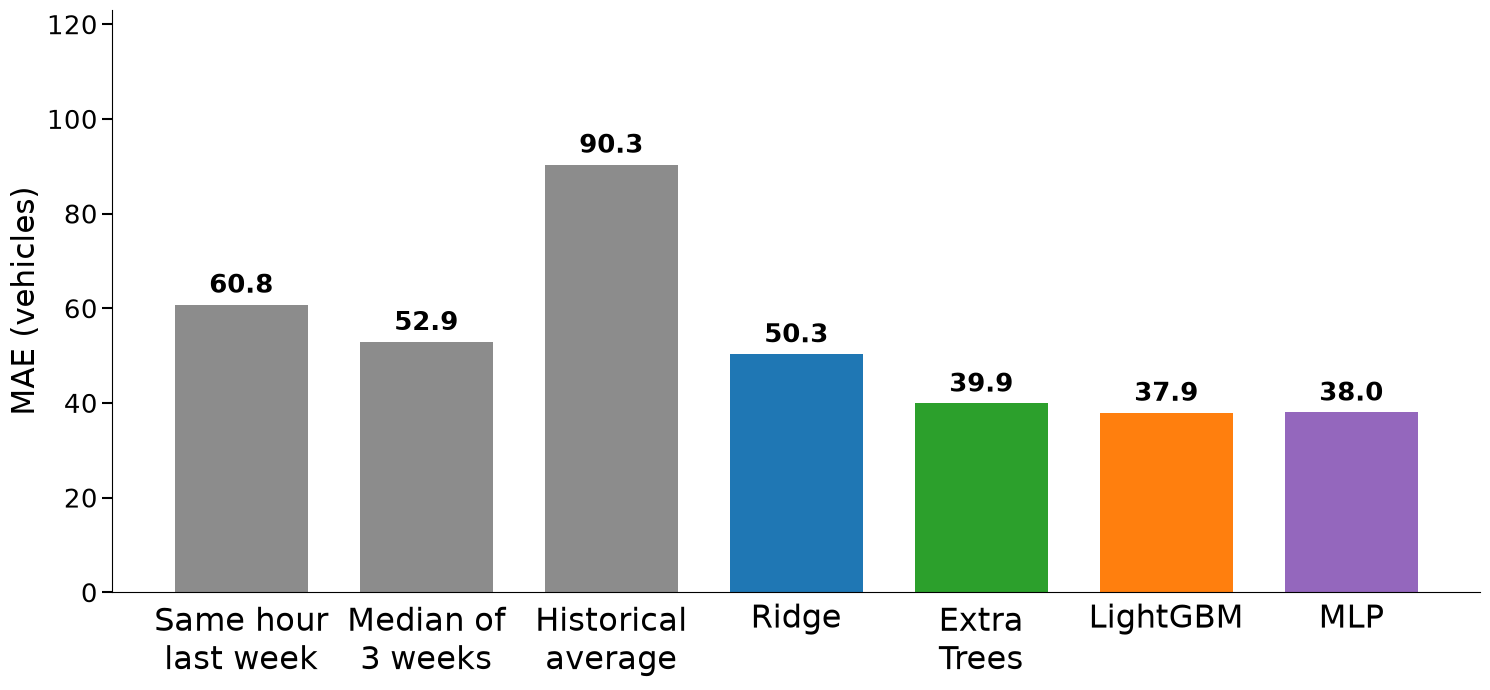

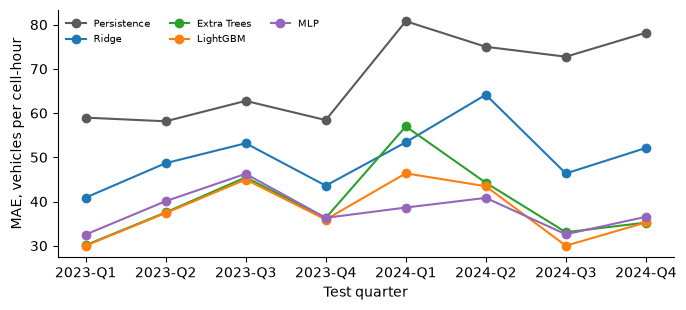

In [9]:
COLORS = {'Ridge': '#1F77B4', 'Extra Trees': '#2CA02C', 'LightGBM': '#FF7F0E', 'MLP': '#9467BD', 'Persistence': '#5A5A5A',
          'Same hour last week': '#8C8C8C', 'Median of 3 weeks': '#8C8C8C', 'Historical Average': '#8C8C8C'}   # baselines share one grey
def clean(ax): ax.spines[['top', 'right']].set_visible(False)
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}', colors=None):
    fig, ax = plt.subplots(figsize=(6.5, 3.2)); cs = colors or ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    b = ax.bar([str(l) for l in labels], values, color=cs); ax.bar_label(b, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8)
    ax.set_ylabel(ylabel); ax.set_ylim(0, np.nanmax(values) * 1.2); clean(ax)
    if len(values) > 6 or max(len(str(l)) for l in labels) > 12: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()
# Figure RQ2: MAE of three baselines (same grey) and four models (one colour each), labels straight, 7 marks on the vertical axis
BL = ['Same hour last week', 'Median of 3 weeks', 'Historical Average']
LAB = {'Same hour last week': 'Same hour\nlast week', 'Median of 3 weeks': 'Median of\n3 weeks', 'Historical Average': 'Historical\naverage', 'Extra Trees': 'Extra\nTrees'}
r2 = res.set_index('model').reindex(BL + MODELS)
xs = np.arange(len(BL) + len(MODELS))                                                       # seven bars, equal spacing
fig, ax = plt.subplots(figsize=(15, 7))
b = ax.bar(xs, r2.MAE, 0.72, color=[COLORS[k] for k in r2.index])
ax.bar_label(b, fmt='%.1f', fontsize=19, fontweight='bold', padding=4)
step = np.ceil(r2.MAE.max() * 1.08 / 6 / 5) * 5; ax.set_yticks(step * np.arange(7)); ax.set_ylim(0, step * 6.15)
ax.set_xticks(xs); ax.set_xticklabels([LAB.get(k, k) for k in r2.index], fontsize=23)
ax.tick_params(axis='y', labelsize=19, length=7, width=1.5); ax.tick_params(axis='x', length=0, pad=8)
ax.set_ylabel('MAE (vehicles)', fontsize=22); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq2_models.png', dpi=300, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(7, 3.2))
for m in REFS[:1] + MODELS:
    g = byfold[byfold.model == m]; ax.plot(g.fold, g.MAE, marker='o', label=m, color=COLORS[m])
ax.set_ylabel('MAE, vehicles per cell-hour'); ax.set_xlabel('Test quarter'); ax.legend(frameon=False, fontsize=7, ncol=3); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq2_by_fold.png', dpi=300); plt.show()

## Bước 6b. RQ3a: thang sửa dữ liệu

- **Làm gì:** so sáu bậc R0–R5 trên **cùng các ô và giờ** (những giờ mà cả bảng chưa sửa cũng có đủ đầu vào), so với **giờ kế tiếp thật**. Bảng thứ hai tách theo nhóm ngày.
- **Cách đọc:** con số cần đọc là mức chênh giữa hai bậc liền nhau (`change_from_previous`). Giá trị âm là bước sửa giúp giảm sai số. Mức chênh chỉ có nghĩa khi lớn hơn dao động giữa các quý.
- **Kiểm tra:** nếu một bậc làm sai số tăng, ghi đúng như vậy và tìm nguyên nhân ở Bước 6c và 6d. Không chỉnh code để ra kết quả mong muốn.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

model,Extra Trees,LightGBM,MLP,Ridge,mean,change_from_previous
repair_step,,,,,,
R0 raw records,42.48,40.85,41.66,59.44,46.11,NaN
R1 + one row per cell and hour,42.48,40.85,41.66,59.44,46.11,0.00
R2 + hourly grid,39.91,38.07,38.86,50.72,41.89,-4.22
R3 + outage and faulty hours left out,39.64,38.10,38.40,50.79,41.73,-0.15
R4 + calendar,39.31,37.51,37.77,50.18,41.19,-0.54
R5 + holiday-aware weekly lag,38.65,37.08,38.72,48.80,40.81,-0.38


group,arife,bridge_day,holiday,ordinary,week_after_holiday
repair_step,,,,,
R0 raw records,48.57,54.09,35.08,46.31,50.68
R1 + one row per cell and hour,48.57,54.09,35.08,46.31,50.68
R2 + hourly grid,50.04,41.30,39.59,41.19,54.72
R3 + outage and faulty hours left out,49.62,40.89,38.78,41.08,54.37
R4 + calendar,50.74,40.41,31.48,40.83,54.18
R5 + holiday-aware weekly lag,52.51,40.95,32.33,41.07,41.79


ladder rows: 2,096,332 of 2,096,332 test rows (100.0%)


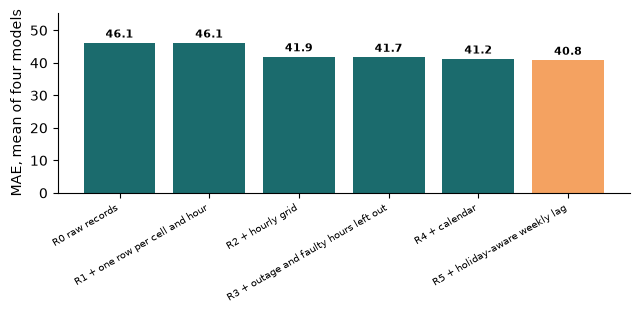

In [10]:
LADDER = ['R0 raw records', 'R1 + one row per cell and hour', 'R2 + hourly grid', 'R3 + outage and faulty hours left out', 'MAIN (R4 + calendar, L0)', 'L2 normal-week lag (R5)']
LAB = {'MAIN (R4 + calendar, L0)': 'R4 + calendar', 'L2 normal-week lag (R5)': 'R5 + holiday-aware weekly lag'}
L = P[P.in_ladder & (P.group != 'special_event')]
rows = []
for cfg in LADDER:
    for m in MODELS:
        e = np.abs(L[f'{cfg}|{m}'] - L.y)
        rows.append({'repair_step': LAB.get(cfg, cfg), 'model': m, 'MAE': float(e.mean()), 'sd_folds': float(e.groupby(L.fold).mean().std())})
lad = pd.DataFrame(rows)
tab = lad.pivot(index='repair_step', columns='model', values='MAE').reindex([LAB.get(c, c) for c in LADDER])
tab['mean'] = tab[MODELS].mean(axis=1); tab['change_from_previous'] = tab['mean'].diff()
save(tab.reset_index().round(3), 'table_rq3_repair_ladder.csv'); display(tab.round(2))
rows = []
for cfg in LADDER:
    for grp, g in L.groupby('group'):
        rows.append({'repair_step': LAB.get(cfg, cfg), 'group': grp, 'MAE_mean_of_models': float(np.mean([np.mean(np.abs(g[f'{cfg}|{m}'] - g.y)) for m in MODELS])), 'rows': len(g)})
labg = pd.DataFrame(rows).pivot(index='repair_step', columns='group', values='MAE_mean_of_models').reindex([LAB.get(c, c) for c in LADDER])
save(labg.reset_index().round(3), 'table_rq3_repair_ladder_by_group.csv'); display(labg.round(2))
print('ladder rows: {:,} of {:,} test rows ({:.1%})'.format(len(L), int((P.group != 'special_event').sum()), len(L) / max(1, int((P.group != 'special_event').sum()))))
bar_chart(tab.index, tab['mean'], 'MAE, mean of four models', REPORT / 'fig_rq3_repair_ladder.png', fmt='{:.1f}', highlight=int(np.nanargmin(tab['mean'].to_numpy())))

## Bước 6c. RQ3b: holiday echo và năm cách xử lý lag tuần

- **Làm gì:** (1) MAE của L0–L4 theo nhóm ngày (ngày thường, ngày lễ, arife, ngày nghỉ bù, **tuần sau lễ**, sự kiện đặc biệt); (2) kiểm định Wilcoxon theo cặp ngày: L0 so với từng phiên bản, trên mọi ngày và riêng các ngày tuần sau lễ; (3) **event study**: sai số theo số ngày kể từ đầu mỗi kỳ lễ, trung bình qua các kỳ lễ trong tập test.
- **Cách đọc:** holiday echo tồn tại nếu L0 có MAE ở nhóm `week_after_holiday` cao rõ hơn nhóm `ordinary`, và đỉnh sai số trong event study rơi vào ngày +7. Hình event study vẽ **chênh lệch so với L0** (L0 = 0): nhịp ngày trong tuần chung cho mọi phiên bản bị triệt tiêu; đường nằm dưới 0 là phiên bản đó tốt hơn L0 vào ngày đó. Số liệu hình nằm ở `table_rq3_event_study_delta.csv`; bảng trong bài (MAE trung bình theo khoảng ngày) nằm ở `table_rq3_event_windows.csv`. Phiên bản nào tốt nhất phải tốt trên **cả** ngày thường lẫn tuần sau lễ; nếu chỉ tốt ở tuần sau lễ mà kém ở ngày thường thì ghi rõ đánh đổi.
- **Kiểm tra:** cột `n_days` của bảng Wilcoxon; dưới 10 ngày thì kết luận yếu.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [11]:
VAR = {'L0': 'MAIN (R4 + calendar, L0)', 'L1': 'L1 no weekly lag', 'L2': 'L2 normal-week lag (R5)', 'L3': 'L3 median of 3 weeks', 'L4': 'L4 weekly lag + holiday flags'}
rows = []
for v, cfg in VAR.items():
    for m in MODELS:
        for grp, g in P.groupby('group'):
            rows.append({'variant': v, 'model': m, 'group': grp, 'MAE': float(np.mean(np.abs(g[f'{cfg}|{m}'] - g.y))), 'rows': len(g)})
var = save(pd.DataFrame(rows), 'table_rq3_weekly_lag_variants.csv')
piv = var.groupby(['variant', 'group']).MAE.mean().unstack(); display(piv.round(2))
# paired test on daily MAE: L0 against every other variant
rows = []
for m in MODELS:
    for v in ['L1', 'L2', 'L3', 'L4']:
        for scope, g in [('all days', P[P.group != 'special_event']), ('week after holiday', P[P.group == 'week_after_holiday'])]:
            d0 = (g[f'{VAR["L0"]}|{m}'] - g.y).abs().groupby(g.day).mean(); d1 = (g[f'{VAR[v]}|{m}'] - g.y).abs().groupby(g.day).mean()
            diff = (d1 - d0).dropna()
            p = wilcoxon(diff).pvalue if len(diff) >= 6 and diff.abs().sum() > 0 else np.nan
            rows.append({'model': m, 'variant_vs_L0': v, 'scope': scope, 'n_days': len(diff), 'median_daily_MAE_change': float(diff.median()) if len(diff) else np.nan,
                         'share_of_days_better': float((diff < 0).mean()) if len(diff) else np.nan, 'p_value': p})
wil = save(pd.DataFrame(rows), 'table_rq3_wilcoxon.csv'); display(wil.round(4))

group,arife,bridge_day,holiday,ordinary,special_event,week_after_holiday
variant,,,,,,
L0,50.74,40.41,31.48,40.83,46.96,54.18
L1,64.76,57.53,30.37,45.53,48.59,46.92
L2,52.51,40.95,32.33,41.07,55.85,41.79
L3,54.94,44.05,35.81,39.50,52.83,41.11
L4,51.01,40.72,31.75,41.58,49.04,54.62


,model,variant_vs_L0,scope,n_days,median_daily_MAE_change,share_of_days_better,p_value
0,Ridge,L1,all days,630,8.0008,0.1556,0.0000
1,Ridge,L1,week after holiday,33,0.3646,0.4848,0.6088
2,Ridge,L2,all days,630,-0.3992,0.7143,0.0000
3,Ridge,L2,week after holiday,33,-5.1463,0.7879,0.0001
4,Ridge,L3,all days,630,-4.3438,0.7683,0.0000
5,Ridge,L3,week after holiday,33,-9.8385,0.9091,0.0000
6,Ridge,L4,all days,630,-0.0714,0.5778,0.0247
7,Ridge,L4,week after holiday,33,-2.7151,0.6667,0.0055
8,Extra Trees,L1,all days,630,1.0842,0.2667,0.0000
9,Extra Trees,L1,week after holiday,33,-0.9569,0.7273,0.0010


16 holiday periods in the test quarters


offset_days,-7,-6,-5,-4,-3,-2,-1,0,1,2,...,5,6,7,8,9,10,11,12,13,14
L0,49.7,50.0,47.0,51.8,41.0,38.2,56.0,38.5,46.3,40.2,...,51.4,39.0,66.8,45.6,55.4,48.4,39.6,41.8,53.0,46.0
L1,55.0,51.1,48.1,52.3,42.9,41.4,61.3,46.1,53.8,42.2,...,44.8,41.1,67.3,46.0,55.8,50.1,39.3,42.5,47.4,51.8
L2,47.0,47.1,44.7,48.3,41.6,38.7,54.4,39.3,46.8,41.2,...,53.9,39.4,58.5,42.3,51.5,45.9,36.1,42.8,55.5,46.1
L3,44.7,47.3,44.9,46.0,38.9,36.7,54.0,40.9,46.3,40.8,...,39.0,37.0,58.3,42.3,51.9,45.1,35.5,38.3,39.3,45.8
L4,49.8,51.5,48.7,53.3,41.5,38.8,60.3,39.2,47.8,41.3,...,54.4,40.2,70.3,46.1,57.0,49.5,40.0,43.4,55.3,47.6


offset_days,-7,-6,-5,-4,-3,-2,-1,0,1,2,...,5,6,7,8,9,10,11,12,13,14
L1,5.30,1.09,1.14,0.42,1.91,3.18,5.33,7.62,7.47,2.06,...,-6.66,2.07,0.44,0.41,0.47,1.72,-0.30,0.65,-5.57,5.79
L2,-2.77,-2.91,-2.29,-3.54,0.54,0.52,-1.60,0.74,0.41,1.08,...,2.47,0.37,-8.33,-3.32,-3.88,-2.52,-3.53,0.98,2.53,0.06
L3,-5.10,-2.73,-2.04,-5.80,-2.14,-1.48,-2.02,2.35,-0.08,0.65,...,-12.46,-2.03,-8.49,-3.34,-3.50,-3.32,-4.11,-3.48,-13.63,-0.20
L4,0.07,1.43,1.71,1.47,0.54,0.63,4.33,0.65,1.44,1.10,...,3.00,1.15,3.52,0.45,1.64,1.08,0.40,1.62,2.34,1.54


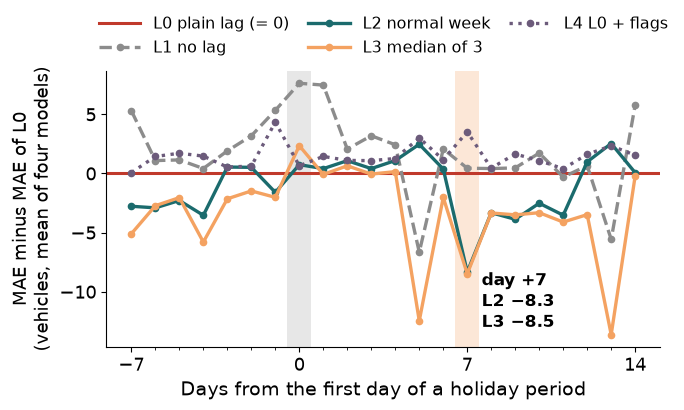

,-7..-1,0,+1..+6,+7,+8..+14
variant,,,,,
L0,47.7,38.5,42.2,66.8,47.1
L1,50.3,46.1,44.0,67.3,47.6
L2,46.0,39.3,43.2,58.5,45.7
L3,44.6,40.9,39.9,58.3,42.6
L4,49.1,39.2,43.7,70.3,48.4


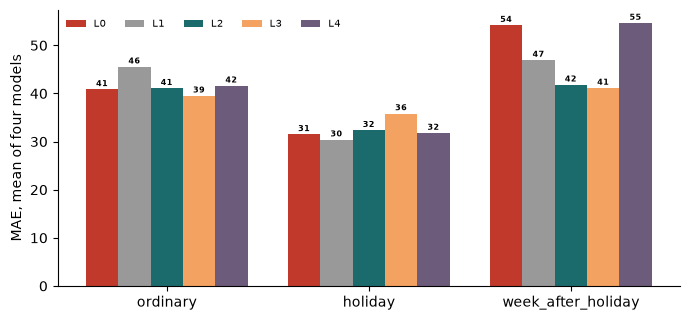

In [12]:
# event study: daily error around each holiday period inside the test quarters
cal = pd.read_parquet(PROC / 'calendar_daily.parquet'); cal['date'] = cal.date.astype('datetime64[ns]')
hl = cal[cal.holiday_like == 1].date.sort_values()
starts = hl[(hl.diff() != pd.Timedelta(days=1))]                                            # first day of each holiday period
test_days = set(P.day.unique()); starts = [s for s in starts if s in test_days]
nonspecial = (P.group != 'special_event').to_numpy()
daily = {v: P.assign(e=np.mean([np.abs(P[f'{cfg}|{m}'] - P.y).to_numpy() for m in MODELS], axis=0))[nonspecial].groupby('day').e.mean() for v, cfg in VAR.items()}
rows = []
for s in starts:
    for off in range(-7, 15):
        d = s + pd.Timedelta(days=off)
        rows.append({'event_start': s.date(), 'offset_days': off, **{v: daily[v].get(d, np.nan) for v in VAR}})
ev = pd.DataFrame(rows); evm = ev.groupby('offset_days')[list(VAR)].mean()
save(ev, 'table_rq3_event_study.csv'); print(len(starts), 'holiday periods in the test quarters'); display(evm.round(1).T)
# Figure: change in daily MAE against L0 (L0 = 0), so the weekday rhythm shared by every variant cancels out
n_per = ev.groupby('offset_days').L0.count().rename('n_periods')            # holiday periods with a scored day at this offset
dlt = evm.sub(evm.L0, axis=0).drop(columns='L0')
save(pd.concat([evm.add_prefix('MAE_'), dlt.add_prefix('dMAE_vs_L0_'), n_per], axis=1).reset_index().round(3), 'table_rq3_event_study_delta.csv')
display(dlt.round(2).T)
STY = {'L1': ('#8C8C8C', '--', 'L1 no lag'), 'L2': ('#1B6B6D', '-', 'L2 normal week'),
       'L3': ('#F4A261', '-', 'L3 median of 3'), 'L4': ('#6C5B7B', ':', 'L4 L0 + flags')}
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.axvspan(-0.5, 0.5, color='#BBBBBB', alpha=.35, lw=0); ax.axvspan(6.5, 7.5, color='#F4A261', alpha=.25, lw=0)
ax.axhline(0, color='#C0392B', lw=2.2, label='L0 plain lag (= 0)')
for v, (c, ls, lab) in STY.items():
    ax.plot(dlt.index, dlt[v], color=c, ls=ls, lw=2.4, marker='o', ms=4.5, label=lab)
ax.text(7.6, min(dlt.loc[7, 'L2'], dlt.loc[7, 'L3']) + 0.3, f'day +7\nL2 {dlt.loc[7, "L2"]:+.1f}\nL3 {dlt.loc[7, "L3"]:+.1f}'.replace('-', '\u2212'),
        fontsize=12.5, fontweight='bold', va='top', ha='left')                  # values read from the table above, not typed by hand
ax.set_xticks(range(-7, 15, 7)); ax.set_xticks(range(-7, 15), minor=True); ax.tick_params(labelsize=13)
ax.set_xlabel('Days from the first day of a holiday period', fontsize=14)
ax.set_ylabel('MAE minus MAE of L0\n(vehicles, mean of four models)', fontsize=13)
ax.legend(frameon=False, fontsize=11.5, ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0), columnspacing=1.2, handlelength=2.6); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq3_event_study.png', dpi=300); plt.show()
# Table for the paper: daily MAE averaged over windows of days around the first day of a holiday period (each day = mean over the periods that have it)
WIN = {'-7..-1': range(-7, 0), '0': [0], '+1..+6': range(1, 7), '+7': [7], '+8..+14': range(8, 15)}
evw = pd.DataFrame({k: evm.loc[list(r), list(VAR)].mean() for k, r in WIN.items()}); evw.index.name = 'variant'
save(evw.reset_index().round(3), 'table_rq3_event_windows.csv'); display(evw.round(1))
g = piv.reindex(columns=['ordinary', 'holiday', 'week_after_holiday'])
fig, ax = plt.subplots(figsize=(7, 3.3)); w = 0.16
for i, v in enumerate(g.index):
    b = ax.bar(np.arange(g.shape[1]) + i * w, g.loc[v], w, label=v, color=['#C0392B', '#999999', '#1B6B6D', '#F4A261', '#6C5B7B'][i])
    ax.bar_label(b, fmt='%.0f', fontsize=6, fontweight='bold', padding=1)
ax.set_xticks(np.arange(g.shape[1]) + 2 * w); ax.set_xticklabels(g.columns); ax.set_ylabel('MAE, mean of four models'); ax.legend(frameon=False, fontsize=7, ncol=5); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq3_weekly_lag_variants.png', dpi=300); plt.show()

### Hình ví dụ holiday echo trên một ô

- **Làm gì:** một ô đông xe (ô có hạng cao nhất còn đủ ít nhất 80% số giờ được chấm), từ 09/06 đến 30/06/2024 quanh Kurban Bayramı: lượng xe thật, lag tuần, dự báo của LightGBM với L0 và L2. Vùng xám: ngày lễ, arife, ngày nghỉ bù; vùng cam: tuần sau lễ.
- **Vì sao:** cho người đọc thấy cơ chế echo trên dữ liệu thật: tuần sau lễ, lag tuần (đường xám đứt) thấp bất thường và kéo dự báo L0 xuống.
- **Kiểm tra:** `report/fig_rq3_echo_example.png`; dòng in ra so MAE của L0 và L2 trên ô này. Đây chỉ là một ví dụ minh hoạ, kết luận chung dựa trên các bảng của Bước 6c.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

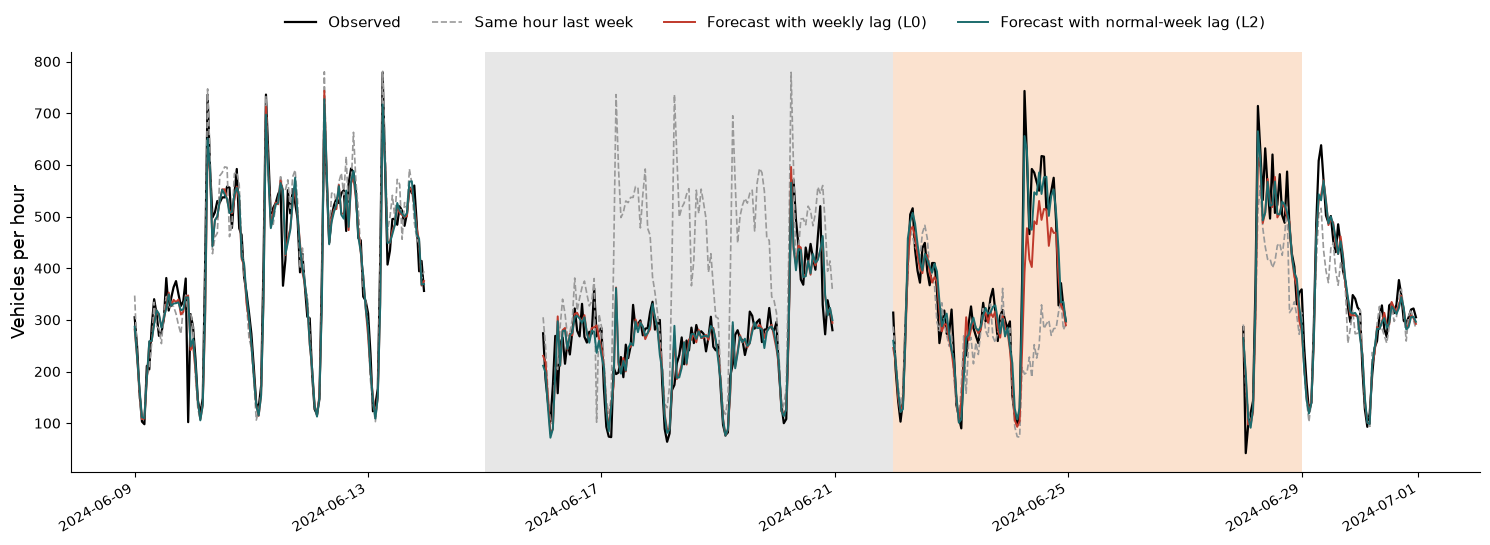

L0: MAE whole window 34.1 | week after the holiday 44.2
L2: MAE whole window 31.3 | week after the holiday 33.8
cell: sxk99p | grey = holiday, arife or bridge day, orange = week after a holiday


In [13]:
# Figure: holiday echo on one busy cell around Kurban Bayrami 2024 (predictions of the main model L0 and of L2, LightGBM)
EX_START, EX_END, EX_MODEL = pd.Timestamp('2024-06-09'), pd.Timestamp('2024-07-01'), 'LightGBM'
win = P[(P.ts_y >= EX_START) & (P.ts_y < EX_END)]
cand_cells = [c for c in cells.sort_values('rank').cell if (win.cell == c).sum() >= 0.8 * 24 * (EX_END - EX_START).days]
EX_CELL = cand_cells[0] if cand_cells else win.cell.value_counts().index[0]          # busiest cell with at least 80% of the hours scored
w = win[win.cell == EX_CELL].sort_values('ts_y').set_index('ts_y').asfreq('h')
calw = cal.set_index('date')
fig, ax = plt.subplots(figsize=(15, 5.5))
for d in pd.date_range(EX_START, EX_END - pd.Timedelta(days=1)):
    r = calw.loc[d] if d in calw.index else None
    if r is not None and r.holiday_like == 1: ax.axvspan(d, d + pd.Timedelta(days=1), color='#BBBBBB', alpha=.35, lw=0)
    elif r is not None and r.week_after_holiday == 1: ax.axvspan(d, d + pd.Timedelta(days=1), color='#F4A261', alpha=.30, lw=0)
ax.plot(w.index, w.y, color='black', lw=1.6, label='Observed')
ax.plot(w.index, w.lag_week_L0, color='#999999', lw=1.2, ls='--', label='Same hour last week')
ax.plot(w.index, w[f'{VAR["L0"]}|{EX_MODEL}'], color='#C0392B', lw=1.4, label='Forecast with weekly lag (L0)')
ax.plot(w.index, w[f'{VAR["L2"]}|{EX_MODEL}'], color='#1B6B6D', lw=1.4, label='Forecast with normal-week lag (L2)')
ax.set_ylabel('Vehicles per hour', fontsize=13); ax.legend(frameon=False, fontsize=11, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.12))
ax.spines[['top', 'right']].set_visible(False); fig.autofmt_xdate()
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq3_echo_example.png', dpi=300, bbox_inches='tight'); plt.show()
ok_e = w.y.notna()
for v in ['L0', 'L2']:
    e = (w[f'{VAR[v]}|{EX_MODEL}'] - w.y).abs()[ok_e]
    wk = w.index[ok_e].normalize().map(lambda d: calw.week_after_holiday.get(d, 0) == 1)
    print(f'{v}: MAE whole window {e.mean():.1f} | week after the holiday {e[wk].mean():.1f}')
print('cell:', EX_CELL, '| grey = holiday, arife or bridge day, orange = week after a holiday')

### Phân rã sai số: vì sao baseline và mô hình lệch khác nhau

- **Làm gì:** cùng một bộ dự báo đã có trong cache (không huấn luyện lại), chia sai số theo ba cách: (1) theo loại ngày, (2) theo giờ trong ngày, (3) một tuần ví dụ trên một ô.
- **So sánh:** 3 baseline (Same hour last week, Median of 3 weeks, Historical Average) và 4 mô hình chính (cấu hình MAIN, L0).
- **Tuần ví dụ:** tự chọn đợt "tuần sau lễ" dài nhất trong các quý test mà ô đông nhất có ít nhất 95% số giờ được chấm; vùng cam là các ngày tuần sau lễ.
- **Kiểm tra:** `table_rq2_error_by_daytype.csv`, `table_rq2_mae_by_hour.csv`, `fig_rq2_mae_by_hour.png`, `fig_rq2_example_week.png`; dòng in cuối cho MAE của từng phương pháp trên ô ví dụ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...


group,ordinary,holiday,week_after_holiday,arife,bridge_day,special_event,echo_ratio
Same hour last week,53.3,135.8,111.9,108.8,132.4,53.6,2.1
Median of 3 weeks,48.2,132.4,52.3,107.0,127.4,42.0,1.1
Historical Average,89.9,80.4,97.9,74.7,83.7,39.0,1.1
Ridge,49.3,39.7,72.8,56.8,40.9,46.8,1.5
Extra Trees,39.2,27.5,49.6,45.5,39.2,36.8,1.3
LightGBM,37.3,28.5,47.9,43.6,42.4,40.9,1.3
MLP,37.5,30.2,46.5,57.0,39.3,63.3,1.2


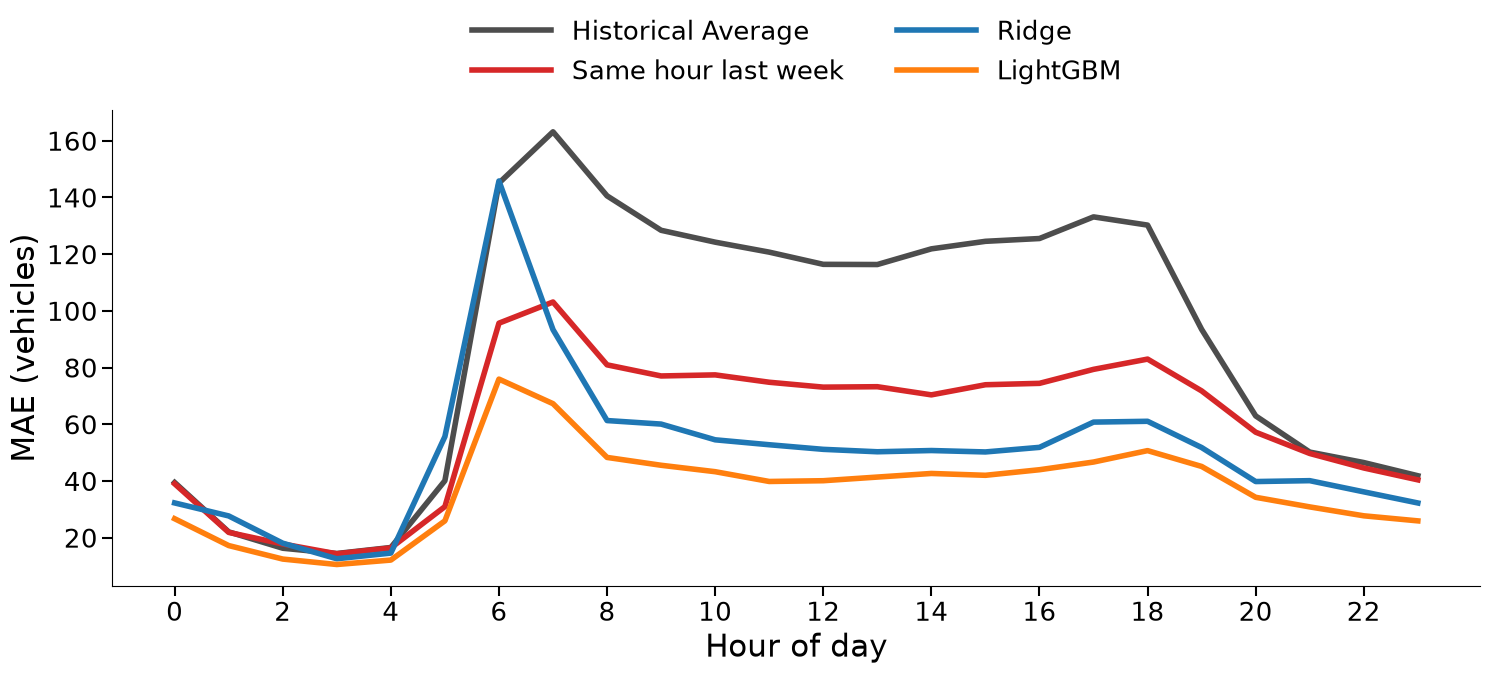

hour with the largest error: {'Same hour last week': 7, 'Median of 3 weeks': 7, 'Historical Average': 7, 'Ridge': 6, 'Extra Trees': 6, 'LightGBM': 6, 'MLP': 6}


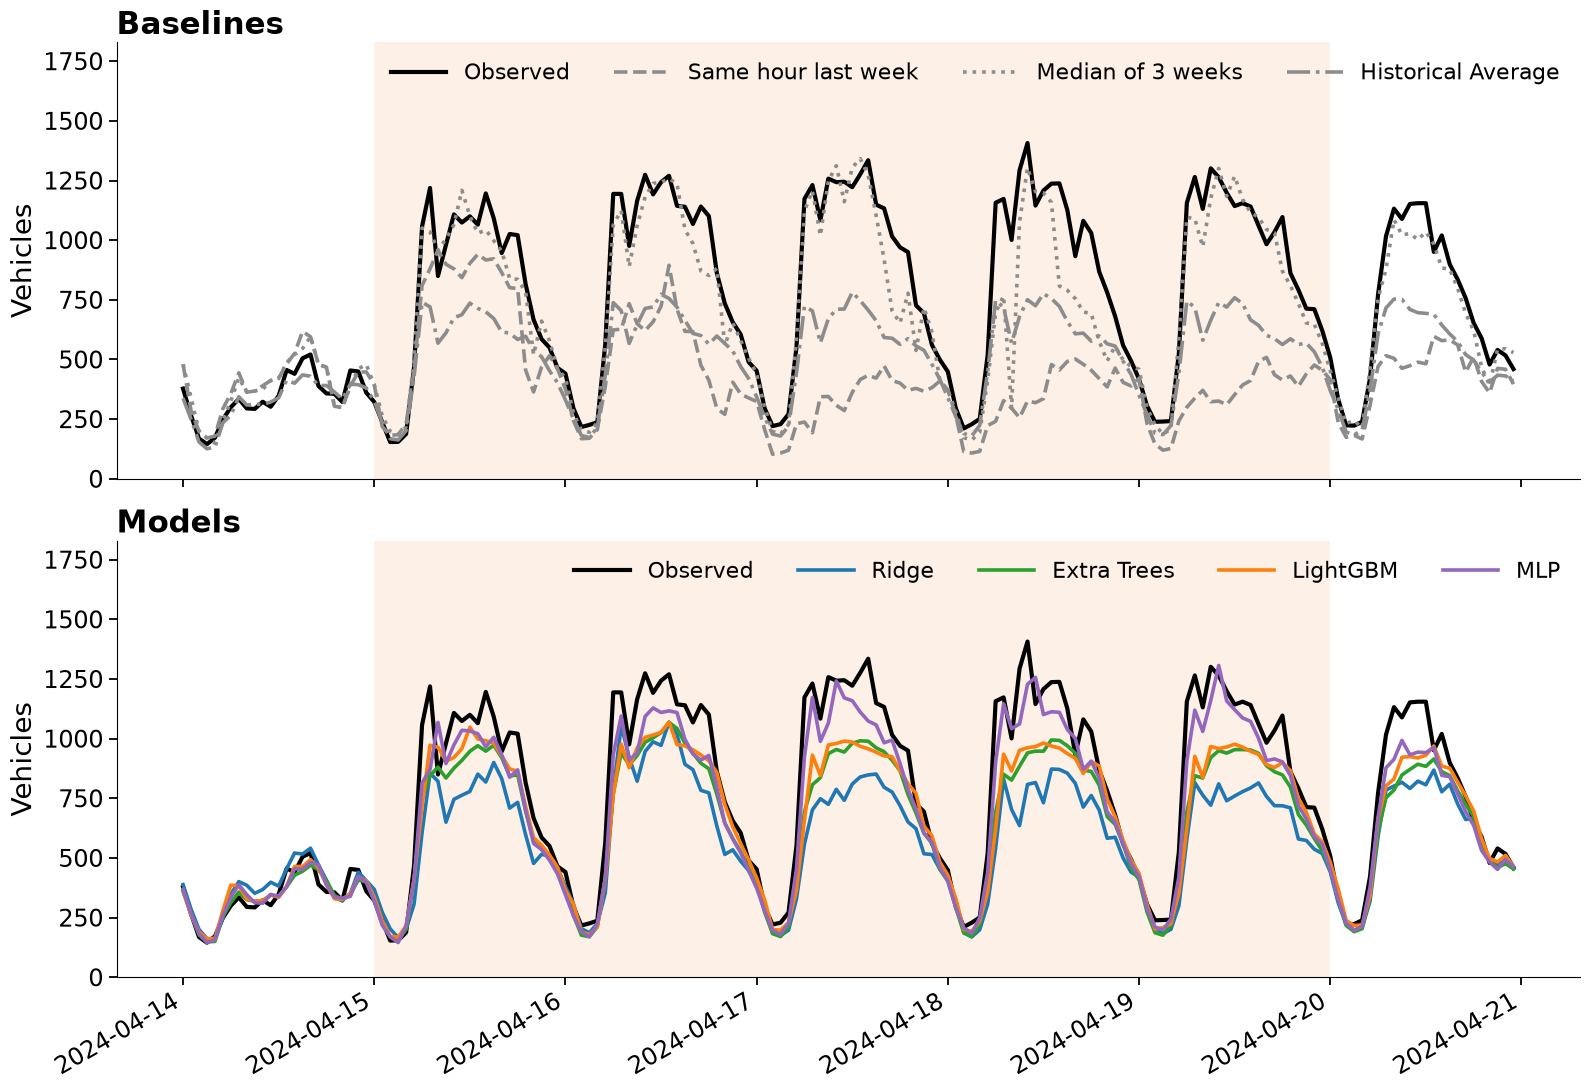

cell sxk3xe (rank 1 ) | week after the holiday 2024-04-15 - 2024-04-19 (orange) | MAE on this cell in that week: {'Same hour last week': 415.4, 'Median of 3 weeks': 98.8, 'Historical Average': 298.0, 'Ridge': 231.1, 'Extra Trees': 153.9, 'LightGBM': 138.0, 'MLP': 91.6}


In [14]:
# Error breakdown: why baselines and models miss by different amounts (by day type, by hour of the day, one example week)
METH = {'Same hour last week': 'Same hour last week', 'Median of 3 weeks': 'Median of 3 weeks', 'Historical Average': 'Historical Average',
        **{m: f'{VAR["L0"]}|{m}' for m in MODELS}}
BSTYLE = {'Same hour last week': '--', 'Median of 3 weeks': ':', 'Historical Average': '-.'}
# 1) MAE by day type
GORDER = ['ordinary', 'holiday', 'week_after_holiday', 'arife', 'bridge_day', 'special_event']
dt_all = pd.DataFrame({k: (P[c] - P.y).abs().groupby(P.group).mean() for k, c in METH.items()}).T
dt_all = dt_all.reindex(columns=[g for g in GORDER if g in dt_all.columns]); dt_all['echo_ratio'] = dt_all.week_after_holiday / dt_all.ordinary
save(dt_all.round(2).rename_axis('method').reset_index(), 'table_rq2_error_by_daytype.csv'); display(dt_all.round(1))
# 2) MAE by hour of the day (target hour, special events left out)
mh = P[P.group != 'special_event']
hr = pd.DataFrame({k: (mh[c] - mh.y).abs().groupby(mh.ts_y.dt.hour).mean() for k, c in METH.items()})
save(hr.round(2).rename_axis('hour').reset_index(), 'table_rq2_mae_by_hour.csv')
fig, ax = plt.subplots(figsize=(15, 7))
HCOL = {'Historical Average': '#4D4D4D', 'Same hour last week': '#D62728', 'Ridge': COLORS['Ridge'], 'LightGBM': COLORS['LightGBM']}   # 4 most telling lines, all solid
for k, c in HCOL.items(): ax.plot(hr.index, hr[k], color=c, lw=4, label=k)
ax.set_xticks(range(0, 24, 2)); ax.tick_params(labelsize=19, length=7, width=1.5)
ax.set_xlabel('Hour of day', fontsize=22); ax.set_ylabel('MAE (vehicles)', fontsize=22)
ax.legend(frameon=False, fontsize=19, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.24), handlelength=3); clean(ax)
fig.tight_layout(); fig.savefig(REPORT / 'fig_rq2_mae_by_hour.png', dpi=300, bbox_inches='tight'); plt.show()
print('hour with the largest error:', {k: int(hr[k].idxmax()) for k in METH})
# 3) one example week: the longest week-after-holiday run in the test quarters where the busiest cells have >= 95% of the hours scored
one = pd.Timedelta(days=1); rank = cells.set_index('cell')['rank']
wa_all = sorted(d for d in P.day.unique() if d in calw.index and calw.loc[d, 'week_after_holiday'] == 1)
runs = []
for d in wa_all:
    if runs and d - runs[-1][-1] == one: runs[-1].append(d)
    else: runs.append([d])
pick = None
for r in sorted(runs, key=len, reverse=True):
    W0, W1 = r[0] - one, r[-1] + 2 * one                                                    # one day before and one day after the run
    cov = P[(P.ts_y >= W0) & (P.ts_y < W1)].groupby('cell').size() / ((W1 - W0) / pd.Timedelta(hours=1))
    ok = cov[cov >= 0.95].index
    if len(ok): pick = (r, W0, W1, rank[ok].idxmin()); break
wa, W0, W1, EX2_CELL = pick
w2 = P[(P.cell == EX2_CELL) & (P.ts_y >= W0) & (P.ts_y < W1)].sort_values('ts_y').set_index('ts_y').asfreq('h')
fig, axs = plt.subplots(2, 1, figsize=(16, 11), sharex=True, sharey=True)
axs[0].set_ylim(0, np.nanmax(w2[['y'] + list(METH.values())].to_numpy(dtype=float)) * 1.3)                # head room for the legend
for ax, keys, title in [(axs[0], BL, 'Baselines'), (axs[1], MODELS, 'Models')]:
    ax.axvspan(wa[0], wa[-1] + one, color='#F4A261', alpha=.15, lw=0)
    ax.plot(w2.index, w2.y, color='black', lw=3, label='Observed')
    for k in keys: ax.plot(w2.index, w2[METH[k]], color=COLORS[k], ls=BSTYLE.get(k, '-'), lw=2.6, label=k)
    ax.set_title(title, fontsize=22, fontweight='bold', loc='left'); ax.set_ylabel('Vehicles', fontsize=20)
    ax.tick_params(labelsize=17, length=6, width=1.3); ax.legend(frameon=False, fontsize=16, ncol=5, loc='upper right', handlelength=2.5); clean(ax)
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(REPORT / 'fig_rq2_example_week.png', dpi=300, bbox_inches='tight'); plt.show()
okw = w2.y.notna() & w2.index.normalize().isin(wa)
print('cell', EX2_CELL, '(rank', int(rank[EX2_CELL]), ') | week after the holiday', wa[0].date(), '-', wa[-1].date(), '(orange) | MAE on this cell in that week:',
      {k: round(float((w2[c] - w2.y).abs()[okw].mean()), 1) for k, c in METH.items()})


## Bước 6d. Kiểm chứng cơ chế và con số lạc quan

- **Làm gì:** (1) với cấu hình chính, mỗi quý ghi hệ số chuẩn hoá của Ridge và tỷ trọng gain của LightGBM cho lag tuần, cạnh các đầu vào khác; (2) MAE theo nhóm ngày của cấu hình chính cho từng mô hình; (3) **con số lạc quan**: MAE mà một notebook bỏ qua bước sửa sẽ báo (chấm trên "dòng kế tiếp") so với MAE thật trên giờ kế tiếp.
- **Vì sao:** (1) kiểm chứng trực tiếp mắt xích "mô hình dựa nặng vào lag tuần"; (3) cho biết bỏ qua bước sửa làm con số báo cáo đẹp hơn thực tế bao nhiêu.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [15]:
rows = []
for e in EX:
    rc, lg = e['ridge_coef'], e['lgb_gain_share']
    rows.append({'fold': e['fold'], 'ridge_coef_weekly_lag': rc.get('lag_week_L0'), 'ridge_coef_volume': rc.get('volume'), 'ridge_coef_lag23': rc.get('lag23'),
                 'lgb_gain_share_weekly_lag': lg.get('lag_week_L0'), 'lgb_gain_share_volume': lg.get('volume'), 'lgb_gain_share_lag23': lg.get('lag23')})
mech = pd.DataFrame(rows)
save(mech.round(4), 'table_rq3_mechanism.csv'); display(mech.round(3))
dt = var[var.variant == 'L0'].pivot(index='model', columns='group', values='MAE')
dt['echo_ratio'] = dt['week_after_holiday'] / dt['ordinary'] if {'week_after_holiday', 'ordinary'} <= set(dt.columns) else np.nan; save(dt.reset_index().round(3), 'table_rq3_error_by_daytype.csv'); display(dt.round(2))
L = P[P.in_ladder & (P.group != 'special_event') & P.y_rec_R0.notna()]
rows = []
for m in MODELS:
    p = L[f'R0 raw records|{m}']
    rows.append({'model': m, 'MAE_scored_on_next_record': float(np.mean(np.abs(p - L.y_rec_R0))), 'MAE_true_next_hour_raw': float(np.mean(np.abs(p - L.y))),
                 'MAE_true_next_hour_repaired': float(np.mean(np.abs(L[f'{VAR["L0"]}|{m}'] - L.y))), 'MAE_true_next_hour_L2': float(np.mean(np.abs(L[f'{VAR["L2"]}|{m}'] - L.y)))})
opt = save(pd.DataFrame(rows), 'table_rq3_optimism.csv'); display(opt.round(2))

,fold,ridge_coef_weekly_lag,ridge_coef_volume,ridge_coef_lag23,lgb_gain_share_weekly_lag,lgb_gain_share_volume,lgb_gain_share_lag23
0,2023-Q1,0.187,0.289,0.148,0.565,0.142,0.189
1,2023-Q2,0.198,0.276,0.142,0.579,0.138,0.186
2,2023-Q3,0.183,0.283,0.136,0.557,0.157,0.181
3,2023-Q4,0.173,0.281,0.134,0.507,0.204,0.169
4,2024-Q1,0.174,0.278,0.134,0.474,0.235,0.170
5,2024-Q2,0.192,0.288,0.136,0.499,0.265,0.131
6,2024-Q3,0.181,0.314,0.148,0.421,0.363,0.116
7,2024-Q4,0.195,0.315,0.148,0.446,0.346,0.114


group,arife,bridge_day,holiday,ordinary,special_event,week_after_holiday,echo_ratio
model,,,,,,,
Extra Trees,45.50,39.16,27.54,39.23,36.84,49.60,1.26
LightGBM,43.55,42.39,28.47,37.27,40.93,47.89,1.29
MLP,57.04,39.25,30.20,37.47,63.26,46.46,1.24
Ridge,56.85,40.85,39.71,49.35,46.83,72.76,1.47


,model,MAE_scored_on_next_record,MAE_true_next_hour_raw,MAE_true_next_hour_repaired,MAE_true_next_hour_L2
0,Ridge,59.44,59.44,50.18,48.80
1,Extra Trees,42.48,42.48,39.31,38.65
2,LightGBM,40.85,40.85,37.51,37.08
3,MLP,41.66,41.66,37.77,38.72


## Bước 6e. Mức ảnh hưởng của các nhóm yếu tố (4 mô hình)

- **Làm gì:** với cấu hình chính (R4 + lịch, lag tuần L0), mô hình seed 0, mỗi quý: xáo trộn cùng lúc mọi cột của một nhóm yếu tố trên mẫu test (mọi giờ tuần sau lễ cộng tối đa 100 nghìn giờ ngày thường), làm 3 lần, đo MAE tăng bao nhiêu (Δ) riêng cho **ngày thường** và **tuần sau lễ**; lấy trung bình 8 quý.
- **Năm nhóm:** Recent traffic (`volume`, `lag1`, `lag2`, `speed`), Same hour last week (`lag_week_L0`), Same hour yesterday (`lag23`), Time of day/week (`hour_sin`, `hour_cos`, `dow_y`, `is_weekend_y`), All other (cờ lịch, `cell_mean`, `lat`, `lon`, `cell`).
- **Công thức:** ngày thường dùng tỷ trọng $s_g = \max(\Delta_g,0) / \sum_k \max(\Delta_k,0) \times 100\%$; tuần sau lễ dùng $r_g = \Delta_g / \text{MAE}_0 \times 100\%$, **có thể âm**: âm nghĩa là bỏ nhóm đó đi thì dự báo tốt hơn, tức nhóm đó đang làm hại (holiday echo). Phương pháp: permutation importance theo nhóm (Breiman 2001; Fisher và cộng sự 2019).
- **Cách đọc:** đây là mức mô hình **dựa vào** từng nhóm, không phải quan hệ nhân quả với lưu lượng. Kết luận mạnh khi cả 4 mô hình cùng một xu hướng.
- **Kiểm tra:** `table_rq3_feature_impact.csv` và 4 hình `fig_impact_<model>.png`.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [16]:
FACTORS = ['Recent traffic', 'Same hour last week', 'Same hour yesterday', 'Time of day/week', 'All other']
rows = []
for e in EX:
    for mname, d in e.get('impact', {}).items():
        for k, v in d.items():
            grp, dg = k.split('|'); rows.append({'fold': e['fold'], 'model': mname, 'factor': grp, 'day_group': dg, **v})
imp = pd.DataFrame(rows).dropna(subset=['delta'])
agg = imp.groupby(['model', 'day_group', 'factor']).agg(delta=('delta', 'mean'), delta_sd_folds=('delta', 'std'), mae0=('mae0', 'mean'), folds=('fold', 'nunique')).reset_index()
agg['change_pct'] = 100 * agg.delta / agg.mae0                                                     # r_g: % change of the error when the factor is shuffled
pos = agg.delta.clip(lower=0); agg['share_pct'] = 100 * pos / pos.groupby([agg.model, agg.day_group]).transform('sum')   # s_g: share of the positive impact
save(agg.round(4), 'table_rq3_feature_impact.csv')
display(agg[agg.day_group == 'ordinary'].pivot(index='factor', columns='model', values='share_pct').reindex(FACTORS).round(1))
display(agg[agg.day_group == 'week_after_holiday'].pivot(index='factor', columns='model', values='change_pct').reindex(FACTORS).round(1))

model,Extra Trees,LightGBM,MLP,Ridge
factor,,,,
Recent traffic,51.0,57.8,49.4,42.8
Same hour last week,11.1,13.1,17.5,33.1
Same hour yesterday,9.7,11.1,15.6,20.2
Time of day/week,25.1,15.3,15.6,3.3
All other,3.1,2.7,1.8,0.6


model,Extra Trees,LightGBM,MLP,Ridge
factor,,,,
Recent traffic,145.7,168.1,164.8,67.7
Same hour last week,18.4,26.7,45.8,37.2
Same hour yesterday,27.1,34.7,50.8,26.9
Time of day/week,71.0,49.5,50.9,8.6
All other,7.3,7.3,6.0,1.0


### Hình mức ảnh hưởng: mỗi mô hình một hình

- **Mỗi hình (cột đứng):** tỷ trọng ảnh hưởng của 5 nhóm yếu tố, tính riêng cho ngày thường (xanh) và tuần sau lễ (cam); mỗi nhóm ngày cộng lại bằng 100%. Tỷ trọng = phần MAE tăng khi xáo trộn nhóm đó / tổng phần tăng của 5 nhóm (giá trị âm tính là 0).
- **Hình tổng hợp** `fig_impact_weekly_lag_4models.png`: tỷ trọng của nhóm Same hour last week ở cả 4 mô hình.
- **Lưu ý khi đọc:** tỷ trọng là tương đối giữa 5 nhóm; số tuyệt đối (cột `delta`, đơn vị xe) nằm trong `table_rq3_feature_impact.csv`.


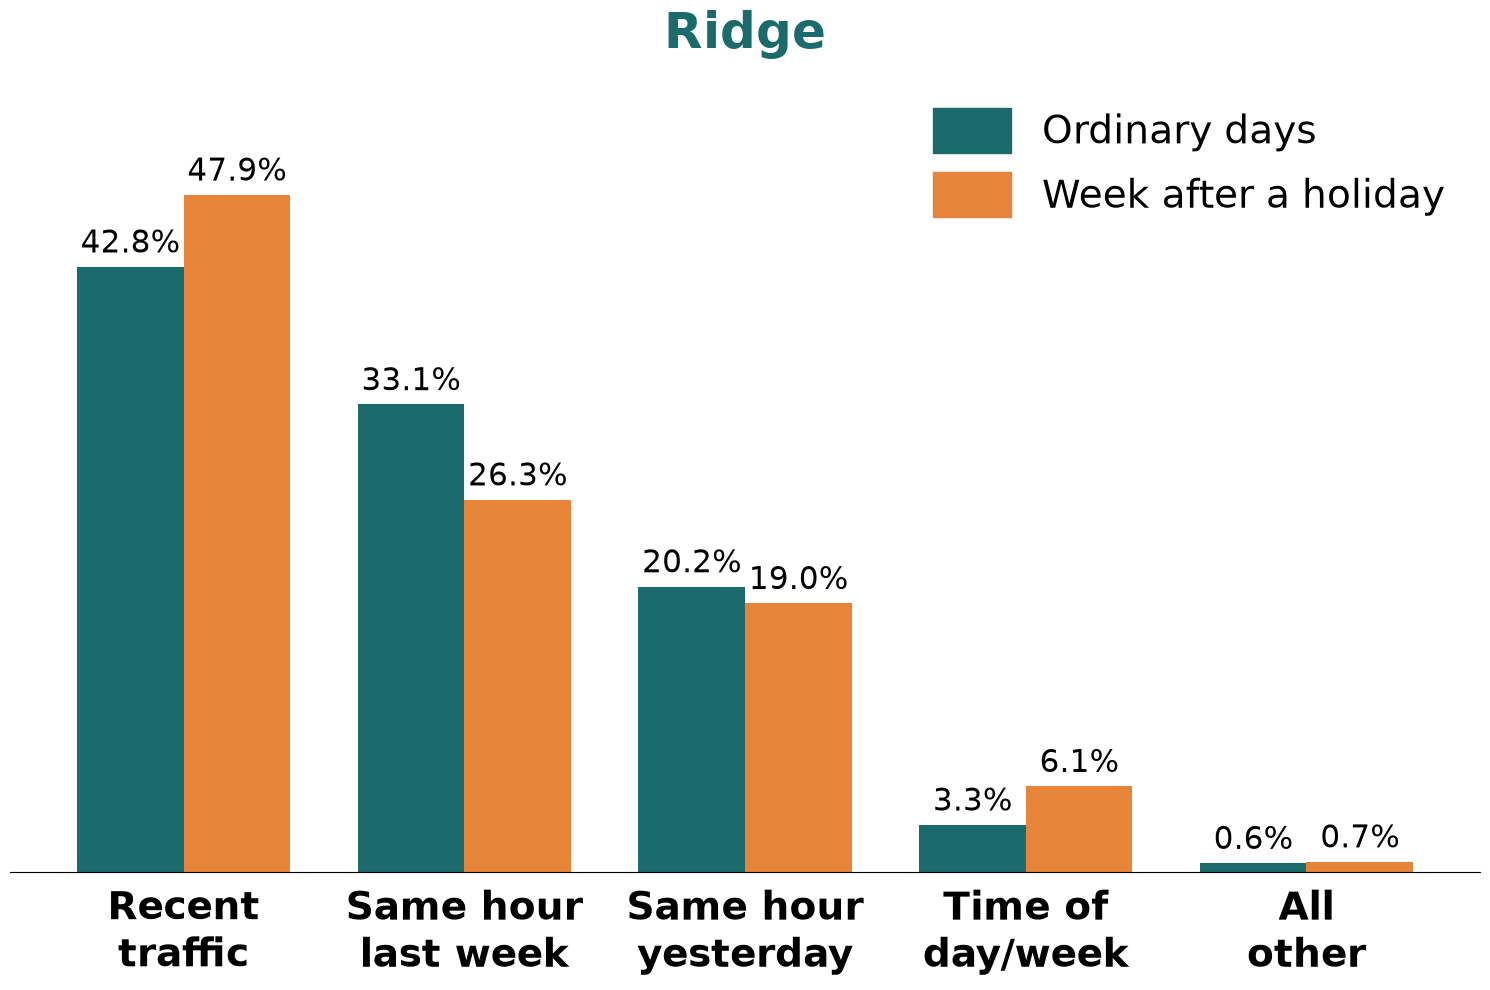

report\fig_impact_Ridge.png


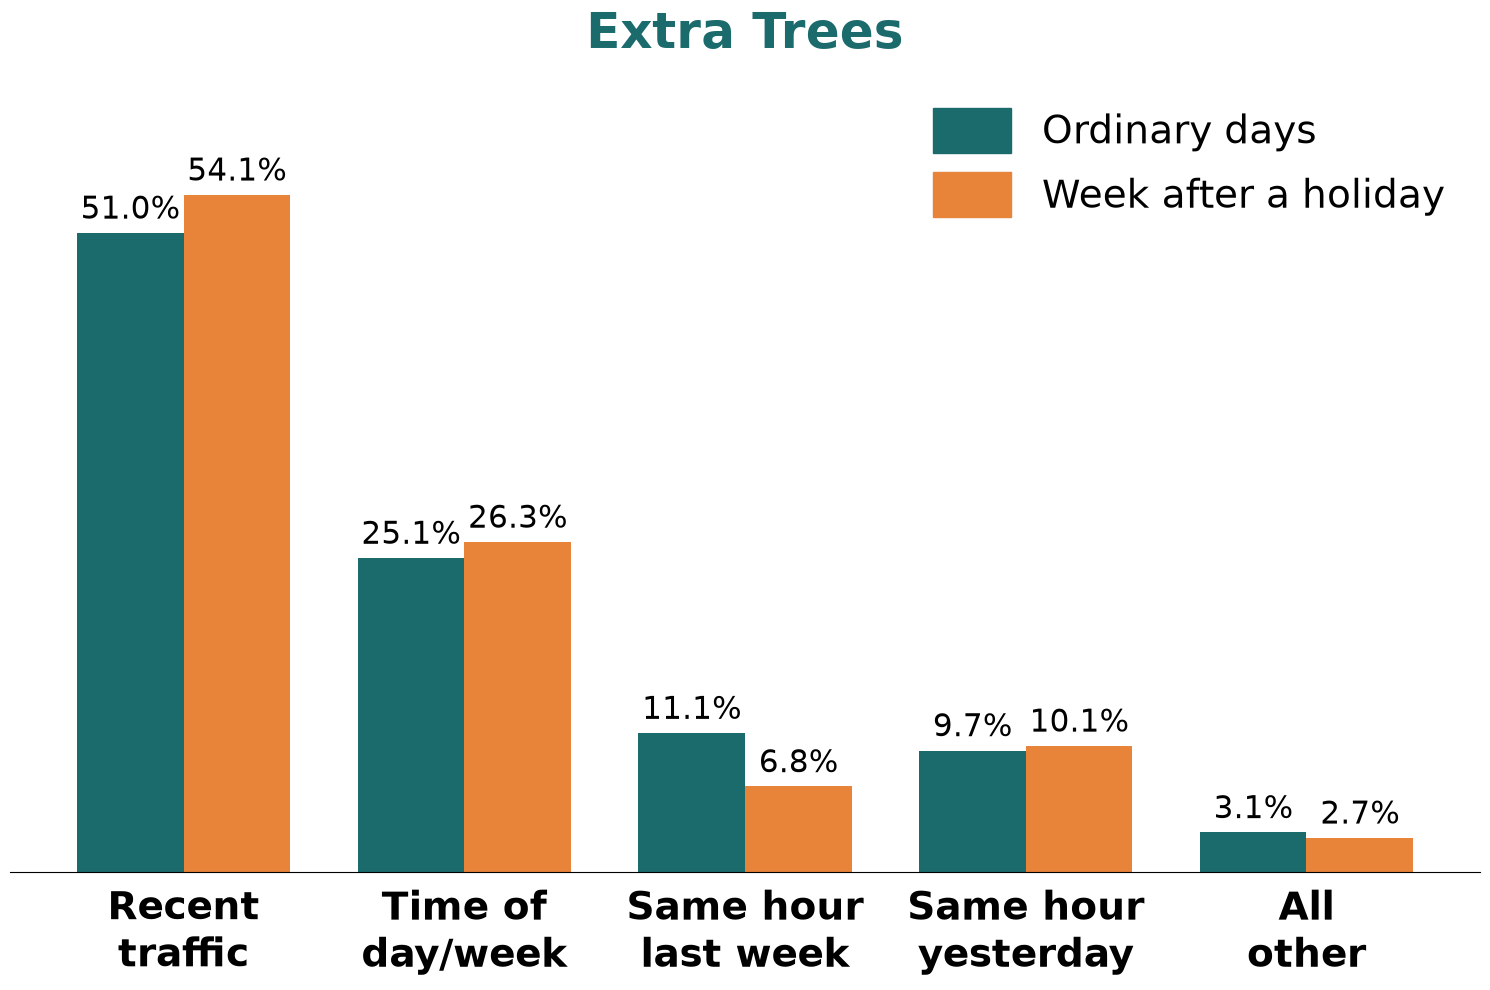

report\fig_impact_Extra_Trees.png


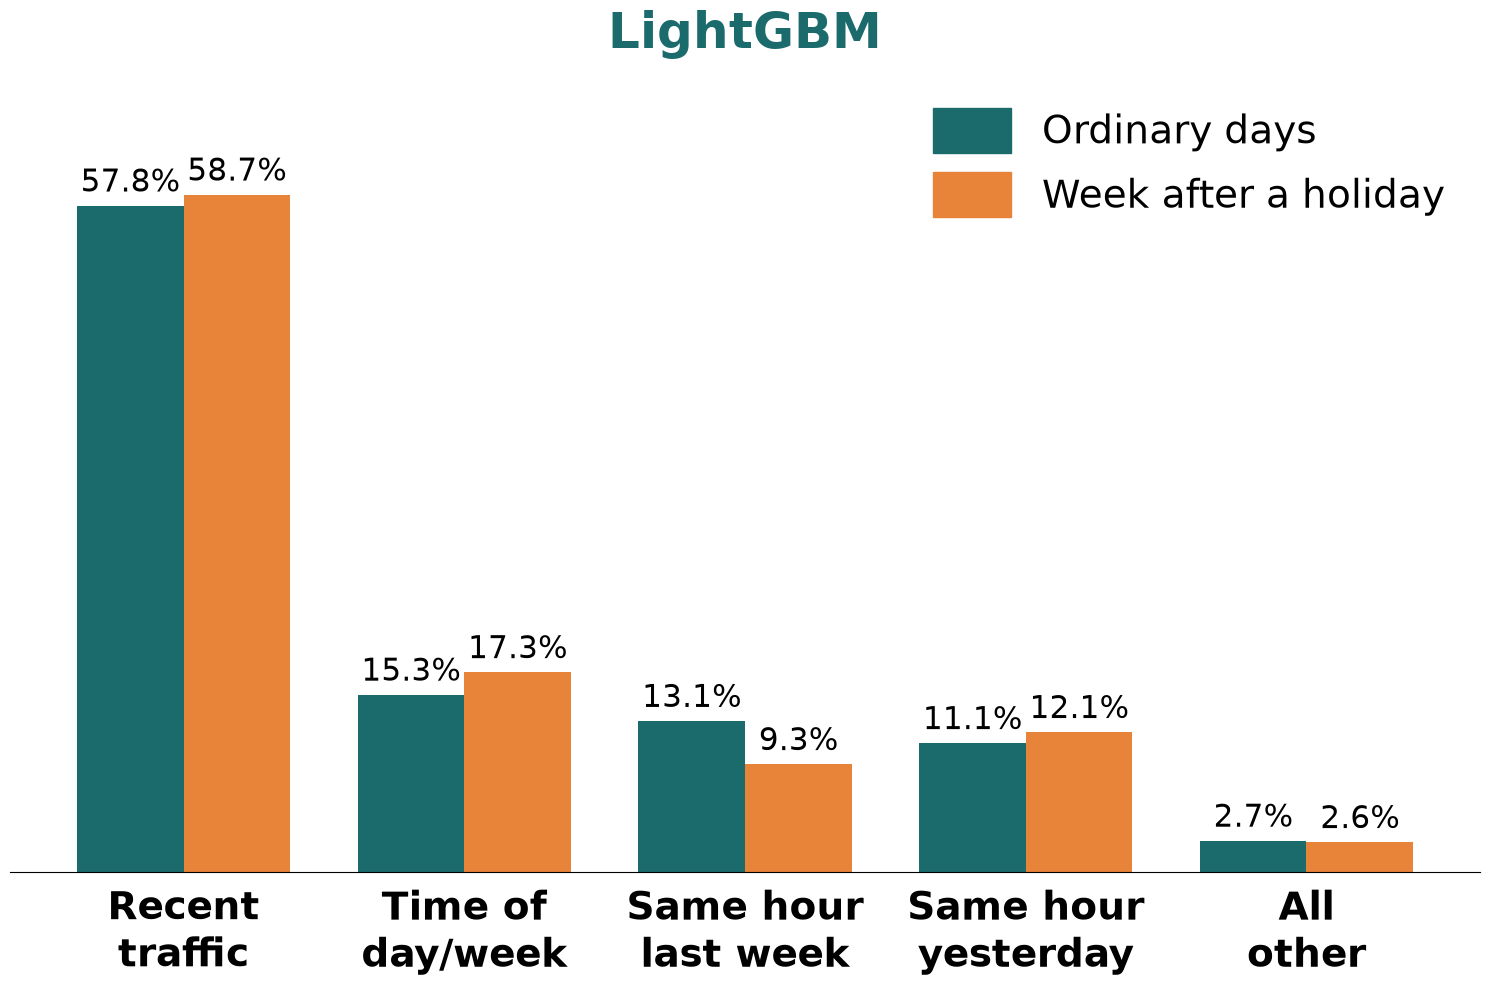

report\fig_impact_LightGBM.png


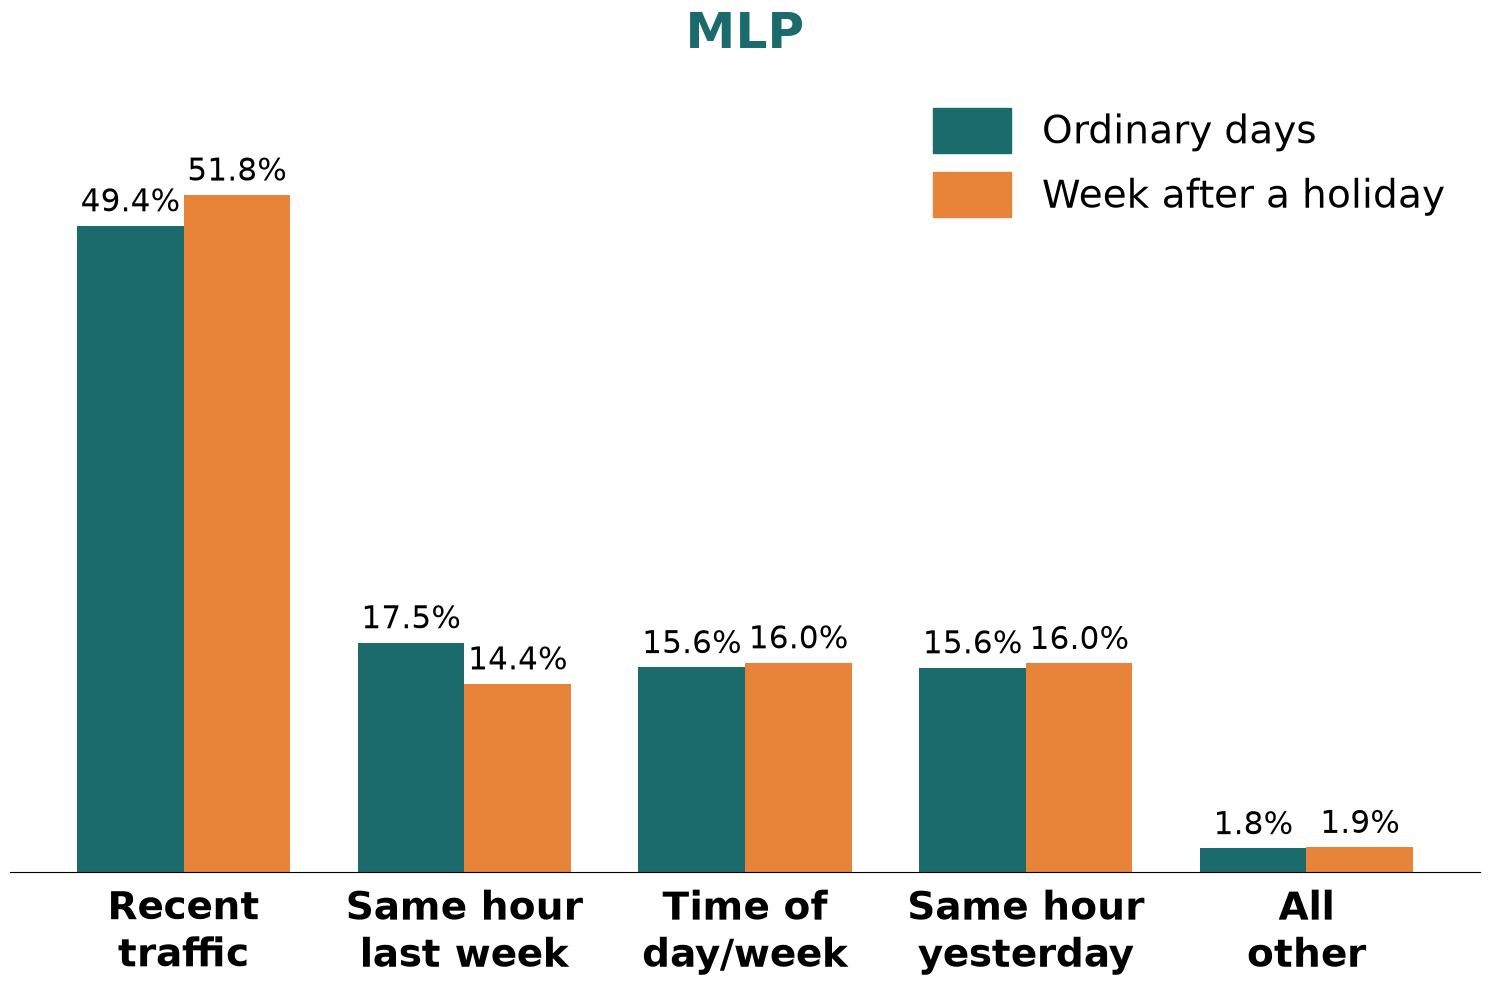

report\fig_impact_MLP.png


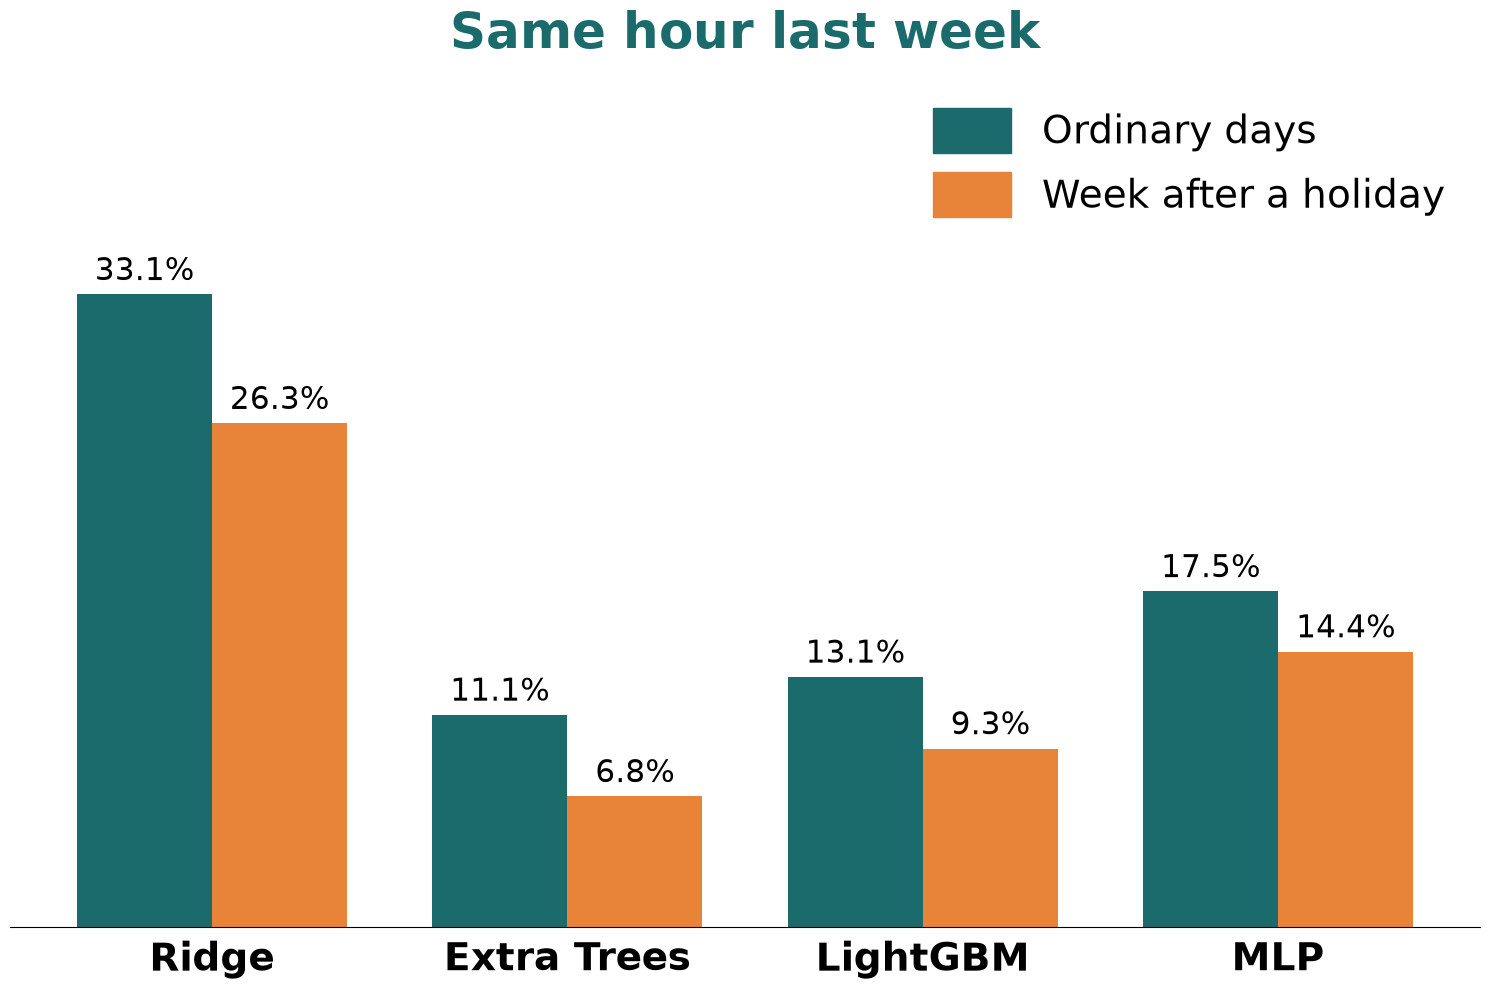

report\fig_impact_weekly_lag_4models.png


In [17]:
# one figure per model (vertical bars): share of the impact (%) of each factor group, ordinary days and week after a holiday (each day group sums to 100%)
TEAL, ORANGE = '#1B6B6D', '#E8833A'
LABEL = {'Recent traffic': 'Recent\ntraffic', 'Time of day/week': 'Time of\nday/week', 'Same hour last week': 'Same hour\nlast week',
         'Same hour yesterday': 'Same hour\nyesterday', 'All other': 'All\nother'}
def shares(a):                                         # positive impact of each factor as a share of the total (sums to 100% per day group)
    p = a.clip(lower=0); return 100 * p / p.sum()
def _legend(ax):
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=TEAL, label='Ordinary days'), Patch(color=ORANGE, label='Week after a holiday')],
              loc='upper right', fontsize=28, frameon=False, handlelength=2.0, handleheight=1.4)
def impact_figure(model):
    a = agg[agg.model == model].pivot(index='factor', columns='day_group', values='delta')
    s = pd.DataFrame({g: shares(a[g]) for g in ['ordinary', 'week_after_holiday']})
    order = [f for f in s.ordinary.sort_values(ascending=False).index if f != 'All other'] + ['All other']
    s = s.reindex(order); x = np.arange(len(order)); w = 0.38
    fig, ax = plt.subplots(figsize=(15, 10))
    b1 = ax.bar(x - w / 2, s.ordinary, w, color=TEAL); b2 = ax.bar(x + w / 2, s.week_after_holiday, w, color=ORANGE)
    ax.bar_label(b1, fmt='%.1f%%', fontsize=22, padding=5); ax.bar_label(b2, fmt='%.1f%%', fontsize=22, padding=5)
    ax.set_xticks(x); ax.set_xticklabels([LABEL.get(f, f) for f in order], fontsize=28, fontweight='bold')
    ax.set_yticks([]); ax.set_ylim(0, np.nanmax(s.values) * 1.18); ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='x', length=0, pad=10)
    ax.set_title(model, fontsize=36, fontweight='bold', color=TEAL, pad=18, loc='center'); _legend(ax)
    fig.tight_layout(); p = REPORT / f"fig_impact_{model.replace(' ', '_')}.png"; fig.savefig(p, dpi=200, bbox_inches='tight'); plt.show(); return p
def weekly_lag_summary():
    rows = {}
    for m in ['Ridge', 'Extra Trees', 'LightGBM', 'MLP']:
        a = agg[agg.model == m].pivot(index='factor', columns='day_group', values='delta')
        rows[m] = {g: shares(a[g]).get('Same hour last week') for g in ['ordinary', 'week_after_holiday']}
    s = pd.DataFrame(rows).T; x = np.arange(len(s)); w = 0.38
    fig, ax = plt.subplots(figsize=(15, 10))
    b1 = ax.bar(x - w / 2, s.ordinary, w, color=TEAL); b2 = ax.bar(x + w / 2, s.week_after_holiday, w, color=ORANGE)
    ax.bar_label(b1, fmt='%.1f%%', fontsize=22, padding=5); ax.bar_label(b2, fmt='%.1f%%', fontsize=22, padding=5)
    ax.set_xticks(x); ax.set_xticklabels(s.index, fontsize=28, fontweight='bold'); ax.set_yticks([]); ax.set_ylim(0, np.nanmax(s.values) * 1.35)
    ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='x', length=0, pad=10)
    ax.set_title('Same hour last week', fontsize=36, fontweight='bold', color=TEAL, pad=18, loc='center'); _legend(ax)
    fig.tight_layout(); p = REPORT / 'fig_impact_weekly_lag_4models.png'; fig.savefig(p, dpi=200, bbox_inches='tight'); plt.show(); return p
for mname in MODELS:
    if mname in set(agg.model): print(impact_figure(mname))
print(weekly_lag_summary())


### Bảng mức ảnh hưởng: 4 mô hình × 5 nhóm yếu tố (ngày thường)

- **Làm gì:** gom kết quả của Bước 6e thành một bảng so sánh 4 mô hình trên ngày thường (ordinary: mọi ngày không phải lễ, arife, ngày nghỉ bù, sự kiện đặc biệt hay tuần sau lễ, gồm cả cuối tuần).
- **Mỗi ô:** tỷ trọng ảnh hưởng (%) của nhóm yếu tố, mỗi cột mô hình cộng lại 100%; trong ngoặc là số xe MAE tăng lên khi xáo trộn nhóm đó. Dòng cuối là MAE trước khi xáo trộn.
- **Kiểm tra:** `report/table_rq3_impact_4models.csv` (cột `*_share_pct` và `*_delta`).

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...


In [18]:
# Table: share of impact (%) of the five factor groups for the four models on ordinary days; in brackets the MAE increase (vehicles) when the group is shuffled
FORDER = ['Recent traffic', 'Same hour last week', 'Same hour yesterday', 'Time of day/week', 'All other']
od = agg[agg.day_group == 'ordinary']
dl = od.pivot(index='factor', columns='model', values='delta').reindex(index=FORDER, columns=MODELS)
sh = 100 * dl.clip(lower=0) / dl.clip(lower=0).sum()                                    # each model column sums to 100%
mae0 = od.groupby('model').mae0.first().reindex(MODELS)
out = pd.concat([sh.round(1).add_suffix('_share_pct'), dl.round(1).add_suffix('_delta')], axis=1)
out = out[[f'{m}_{k}' for m in MODELS for k in ['share_pct', 'delta']]]
save(out.rename_axis('factor').reset_index(), 'table_rq3_impact_4models.csv')
view = sh.round(1).astype(str) + '% (+' + dl.round(1).astype(str) + ')'
view.loc['MAE before shuffling (vehicles)'] = mae0.round(1).astype(str)
display(view)
print('largest factor per model:', {m: sh[m].idxmax() for m in MODELS})


model,Ridge,Extra Trees,LightGBM,MLP
factor,,,,
Recent traffic,42.8% (+49.7),51.0% (+69.1),57.8% (+79.8),49.4% (+73.5)
Same hour last week,33.1% (+38.4),11.1% (+15.0),13.1% (+18.1),17.5% (+26.1)
Same hour yesterday,20.2% (+23.4),9.7% (+13.1),11.1% (+15.4),15.6% (+23.2)
Time of day/week,3.3% (+3.9),25.1% (+34.0),15.3% (+21.2),15.6% (+23.2)
All other,0.6% (+0.7),3.1% (+4.3),2.7% (+3.7),1.8% (+2.7)
MAE before shuffling (vehicles),49.9,40.1,38.2,39.8


largest factor per model: {'Ridge': 'Recent traffic', 'Extra Trees': 'Recent traffic', 'LightGBM': 'Recent traffic', 'MLP': 'Recent traffic'}


## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này (có thể với `FAST = True` trước) và ghi vào ô Đối chứng.

In [19]:
import glob
need = ['table_rq2.csv', 'table_rq2_by_fold.csv', 'table_folds.csv', 'table_rq3_repair_ladder.csv', 'table_rq3_weekly_lag_variants.csv',
        'table_rq3_wilcoxon.csv', 'table_rq3_event_study.csv', 'table_rq3_event_study_delta.csv', 'table_rq3_event_windows.csv', 'table_rq3_mechanism.csv', 'table_rq3_optimism.csv', 'table_rq3_time_axis_artefact.csv', 'table_rq3_feature_impact.csv',
        'table_rq2_error_by_daytype.csv', 'table_rq2_mae_by_hour.csv', 'table_rq3_impact_4models.csv']
missing = [n for n in need if not (REPORT / n).exists()]; assert not missing, missing
assert len(FOLDS) == len(P.fold.unique()), 'some folds have no results'
if FAST: print('WARNING: FAST = True, the numbers are only a smoke test; set FAST = False for the paper')
if best.MASE >= 1: print('WARNING: no model beats persistence on average; check features and split, then report it honestly')
print(sorted(os.path.basename(x) for x in glob.glob(str(REPORT / '*'))))
print('Notebook B: all checks passed')

['cache_v2', 'fig_eda_coverage.png', 'fig_eda_target.png', 'fig_impact_Extra_Trees.png', 'fig_impact_LightGBM.png', 'fig_impact_MLP.png', 'fig_impact_Ridge.png', 'fig_impact_weekly_lag_4models.png', 'fig_map_cells.png', 'fig_pipeline.png', 'fig_rq1_completeness.png', 'fig_rq1_daytype_by_year.png', 'fig_rq1_echo_ratio.png', 'fig_rq1_heatmap_hour_dow.png', 'fig_rq1_hourly_profile.png', 'fig_rq2_by_fold.png', 'fig_rq2_example_week.png', 'fig_rq2_mae_by_hour.png', 'fig_rq2_models.png', 'fig_rq3_echo_example.png', 'fig_rq3_event_study.png', 'fig_rq3_repair_ladder.png', 'fig_rq3_weekly_lag_variants.png', 'table_anomaly_days.csv', 'table_cleaning_log.csv', 'table_eda_by_group.csv', 'table_folds.csv', 'table_monthly_level.csv', 'table_numeric_summary.csv', 'table_q1.csv', 'table_q2.csv', 'table_q3.csv', 'table_q4.csv', 'table_q5.csv', 'table_q7.csv', 'table_rq1_heatmap_hour_dow.csv', 'table_rq1_monthly_profile.csv', 'table_rq2.csv', 'table_rq2_by_fold.csv', 'table_rq2_error_by_daytype.csv', 't

### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn Persistence, hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa các quý, ngày bất thường chưa có trong lịch) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có (MAE và MASE của mô hình tốt nhất, mức chênh của từng bậc sửa, MAE tuần sau lễ của L0 và phiên bản tốt nhất):
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta:

## Kiểm tra độ nhạy: huấn luyện trên toàn bộ dữ liệu (chỉ để xem, không ghi file)

- **Làm gì:** huấn luyện lại Ridge và LightGBM (seed 0) trên **toàn bộ** dòng train có sẵn thay vì 150.000 dòng lấy mẫu, ở 2 quý 2023-Q2 và 2024-Q3, với 2 cấu hình L0 (MAIN) và L2. So MAE với bản 150.000 dòng trong cache, trên **cùng các dòng test**.
- **Cách chạy:** cell này chỉ cần các cell 3 (setup), 5 (bảng đặc trưng) và 11 (mô hình, hàm). Có thể chạy riêng 3 cell đó rồi chạy cell này, hoặc Run All.
- **Không ghi file:** cell không lưu CSV, hình hay cache nào; kết quả chỉ in ra màn hình.
- **Quy tắc đọc (chốt trước khi chạy):** (1) |chênh lệch MAE trên mọi ngày| nhỏ hơn độ lệch chuẩn giữa các quý của mô hình đó (Bảng II); (2) khi dùng toàn bộ dữ liệu, L2 vẫn có MAE tuần sau lễ thấp hơn L0. Cả hai PASS thì kết luận của bài không đổi.
- **Thời gian và RAM (ước lượng):** khoảng 15–30 phút, RAM cao nhất khoảng 3–4 GB. Nên tắt Chrome, Zalo, Claude trước khi chạy.


In [ ]:
# Sensitivity check, PRINT ONLY (writes no file, changes no cache): train on ALL available rows instead of TRAIN_CAP = 150,000 sampled rows
# Needs only cells 3 (setup), 5 (feature table f) and 11 (models and functions). Reads report/cache_v2 and report/table_rq2.csv.
def sensitivity_full_train():
    SENS_FOLDS = {'2023-Q2': ('2023-04-01', '2023-07-01'), '2024-Q3': ('2024-07-01', '2024-10-01')}
    SENS_MODELS = ['Ridge', 'LightGBM']                                   # the two models that fit in 16 GB RAM on all rows
    SENS_CFG = {'L0': 'MAIN (R4 + calendar, L0)', 'L2': 'L2 normal-week lag (R5)'}
    sd_folds = pd.read_csv(REPORT / 'table_rq2.csv').set_index('model').sd_folds   # spread between quarters (Table II), fixed before this check
    out = []
    for q, (s0, s1) in SENS_FOLDS.items():
        start, end = pd.Timestamp(s0), pd.Timestamp(s1)
        te_m = (f.ts >= start) & (f.ts_y < end) & f.score_ok & f.core_ok                  # same test rows as cell 12
        cov = f[(f.ts >= start) & (f.ts_y < end)].groupby('cell').volume.apply(lambda s: s.notna().mean())
        te_m &= f.cell.isin(cov[cov >= MIN_TEST_COVERAGE].index)
        TE = f[te_m].reset_index(drop=True)
        C = pd.read_parquet(CACHE / f'fold_{q}.parquet')                                   # predictions of the 150,000-row fits
        assert len(C) == len(TE) and not C.duplicated(['cell', 'ts']).any(), 'test rows differ from the cache'
        C = C.set_index(['cell', 'ts']).reindex(pd.MultiIndex.from_frame(TE[['cell', 'ts']])).reset_index()   # same rows; the row order of feat.parquet may differ, so align by (cell, hour)
        assert C.y.notna().all(), 'some test rows are missing in the cache'
        y = TE.y.to_numpy(dtype='float64'); assert np.allclose(y, C.y.to_numpy(dtype='float64')), 'targets differ from the cache'
        grp = C.group.to_numpy(); masks = {'all days': grp != 'special_event', 'week after holiday': grp == 'week_after_holiday'}
        mae = lambda pr, mk: float(np.mean(np.abs(pr[mk] - y[mk])))
        for v, cfg in SENS_CFG.items():
            feats, clean = GRID_CFG[cfg]
            need = [c for c in feats if c != 'cell_mean']
            pool = (f.ts_y < start) & f.score_ok & f[need].notna().all(axis=1)
            if clean: pool &= f.clean_now
            TR = f.loc[pool, list(dict.fromkeys(['cell', 'ts', 'ts_y', 'y'] + need))]     # ALL available rows, no sampling, only the needed columns
            assert TR.ts_y.max() < TE.ts.min() + pd.Timedelta(hours=1), 'leakage: a training target is not before the test period'
            TRc, TEc = with_cell_mean(TR, TE)
            for name in SENS_MODELS:
                p, m, secs = fit_predict(name, 0, TRc, TEc, feats, 'y'); p = p.astype('float64')
                old = C[f'{cfg}|{name}|seed0' if cfg.startswith('MAIN') else f'{cfg}|{name}'].to_numpy(dtype='float64')
                r = {'quarter': q, 'model': name, 'variant': v, 'train_rows_150k': min(TRAIN_CAP, int(pool.sum())), 'train_rows_full': int(pool.sum()), 'train_s_full': round(secs, 1)}
                for k, mk in masks.items():
                    r[f'MAE_150k | {k}'] = mae(old, mk); r[f'MAE_full | {k}'] = mae(p, mk); r[f'change | {k}'] = r[f'MAE_full | {k}'] - r[f'MAE_150k | {k}']
                out.append(r); print(f"{q} {name:8s} {v}: {r['train_rows_full']:,} rows, {secs:.0f} s | all days {r['MAE_150k | all days']:.2f} -> {r['MAE_full | all days']:.2f}")
                del m, p
            del TR, TRc, TEc; gc.collect()
    R = pd.DataFrame(out)
    print('\nTable: MAE with 150,000 sampled rows vs all rows (same test rows, seed 0)'); display(R.round(2))
    # rule 1: change on all days smaller than the spread between quarters of that model
    R['sd_folds'] = R.model.map(sd_folds); ok1 = (R['change | all days'].abs() < R.sd_folds)
    print('\nRule 1 (|change| on all days < SD over folds):', 'PASS' if ok1.all() else 'FAIL', '|', ', '.join(f"{a} {b} {c}: {d:+.2f} vs {e:.1f}" for a, b, c, d, e in R[['quarter', 'model', 'variant', 'change | all days', 'sd_folds']].itertuples(index=False)))
    # rule 2: with all rows, L2 still has a lower week-after error than L0 (the 150k gap is shown for comparison)
    W = R.pivot_table(index=['quarter', 'model'], columns='variant', values=['MAE_150k | week after holiday', 'MAE_full | week after holiday'])
    gap_old = W['MAE_150k | week after holiday']['L2'] - W['MAE_150k | week after holiday']['L0']
    gap_new = W['MAE_full | week after holiday']['L2'] - W['MAE_full | week after holiday']['L0']
    G = pd.DataFrame({'L2 - L0 week after, 150k': gap_old, 'L2 - L0 week after, all rows': gap_new}); display(G.round(2))
    print('Rule 2 (with all rows, L2 below L0 in the week after a holiday):', 'PASS' if (gap_new < 0).all() else 'FAIL')
    return R
sens = sensitivity_full_train()

2023-Q2 Ridge    L0: 1,485,711 rows, 1 s | all days 48.67 -> 48.61
2023-Q2 LightGBM L0: 1,485,711 rows, 11 s | all days 37.54 -> 36.89
2023-Q2 Ridge    L2: 1,522,170 rows, 1 s | all days 48.43 -> 48.36
2023-Q2 LightGBM L2: 1,522,170 rows, 11 s | all days 37.51 -> 36.68
2024-Q3 Ridge    L0: 2,724,442 rows, 1 s | all days 46.34 -> 46.66
2024-Q3 LightGBM L0: 2,724,442 rows, 25 s | all days 30.25 -> 28.75
2024-Q3 Ridge    L2: 2,850,282 rows, 1 s | all days 44.98 -> 45.29
2024-Q3 LightGBM L2: 2,850,282 rows, 20 s | all days 29.89 -> 28.29

Table: MAE with 150,000 sampled rows vs all rows (same test rows, seed 0)


,quarter,model,variant,train_rows_150k,train_rows_full,train_s_full,MAE_150k | all days,MAE_full | all days,change | all days,MAE_150k | week after holiday,MAE_full | week after holiday,change | week after holiday
0,2023-Q2,Ridge,L0,150000,1485711,0.6,48.67,48.61,-0.06,49.99,49.59,-0.40
1,2023-Q2,LightGBM,L0,150000,1485711,11.3,37.54,36.89,-0.64,40.07,39.73,-0.33
2,2023-Q2,Ridge,L2,150000,1522170,0.5,48.43,48.36,-0.07,45.89,45.83,-0.06
3,2023-Q2,LightGBM,L2,150000,1522170,10.6,37.51,36.68,-0.83,38.32,37.67,-0.66
4,2024-Q3,Ridge,L0,150000,2724442,1.1,46.34,46.66,0.32,86.12,85.97,-0.14
5,2024-Q3,LightGBM,L0,150000,2724442,25.4,30.25,28.75,-1.51,48.18,43.71,-4.46
6,2024-Q3,Ridge,L2,150000,2850282,1.1,44.98,45.29,0.31,55.76,56.50,0.74
7,2024-Q3,LightGBM,L2,150000,2850282,20.5,29.89,28.29,-1.60,33.25,31.04,-2.20



Rule 1 (|change| on all days < SD over folds): PASS | 2023-Q2 Ridge L0: -0.06 vs 7.2, 2023-Q2 LightGBM L0: -0.64 vs 6.4, 2023-Q2 Ridge L2: -0.07 vs 7.2, 2023-Q2 LightGBM L2: -0.83 vs 6.4, 2024-Q3 Ridge L0: +0.32 vs 7.2, 2024-Q3 LightGBM L0: -1.51 vs 6.4, 2024-Q3 Ridge L2: +0.31 vs 7.2, 2024-Q3 LightGBM L2: -1.60 vs 6.4


L2 - L0 week after, 150k  L2 - L0 week after, all rows
quarter model                                                           
2023-Q2 LightGBM                     -1.74                         -2.07
        Ridge                        -4.10                         -3.76
2024-Q3 LightGBM                    -14.93                        -12.67
        Ridge                       -30.35                        -29.47

Rule 2 (with all rows, L2 below L0 in the week after a holiday): PASS
